# DATASET ACQUISITION AND LOADING

In [ ]:

# ============================================================
# STEP 1: UCI-HAR DATASET ACQUISITION AND LOADING
# Dataset Path: G:\Work\5137\UCI-HAR Dataset
# ============================================================

import os
import numpy as np
import pandas as pd

# Dataset directory
DATASET_PATH = r"G:\Work\5137\UCI-HAR Dataset"

# Required dataset files
required_files = [
    "train/X_train.txt",
    "train/y_train.txt",
    "train/subject_train.txt",
    "test/X_test.txt",
    "test/y_test.txt",
    "test/subject_test.txt",
    "activity_labels.txt",
    "features.txt",
    "features_info.txt",
    "README.txt"
]

print("=" * 65)
print("STEP 1: UCI-HAR DATASET ACQUISITION")
print("=" * 65)

# 1. Verify dataset directory
if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_PATH}\n"
        "Check the folder path and drive."
    )

# 2. Check required files
missing_files = []

for file_name in required_files:
    full_path = os.path.join(DATASET_PATH, file_name)

    if os.path.isfile(full_path):
        print(f"[FOUND] {file_name}")
    else:
        print(f"[MISSING] {file_name}")
        missing_files.append(file_name)

if missing_files:
    raise FileNotFoundError(
        "Required dataset files are missing:\n"
        + "\n".join(missing_files)
        + "\nCheck the folder structure before proceeding."
    )

# 3. Load training data
X_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train/X_train.txt"),
    sep=r"\s+",
    header=None
)

y_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train/y_train.txt"),
    sep=r"\s+",
    header=None
).iloc[:, 0]

subject_train = pd.read_csv(
    os.path.join(DATASET_PATH, "train/subject_train.txt"),
    sep=r"\s+",
    header=None
).iloc[:, 0]

# 4. Load testing data
X_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test/X_test.txt"),
    sep=r"\s+",
    header=None
)

y_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test/y_test.txt"),
    sep=r"\s+",
    header=None
).iloc[:, 0]

subject_test = pd.read_csv(
    os.path.join(DATASET_PATH, "test/subject_test.txt"),
    sep=r"\s+",
    header=None
).iloc[:, 0]

# 5. Load feature names
feature_info = pd.read_csv(
    os.path.join(DATASET_PATH, "features.txt"),
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature_name"]
)

feature_names = feature_info["feature_name"].tolist()

# 6. Load activity labels
activity_labels = pd.read_csv(
    os.path.join(DATASET_PATH, "activity_labels.txt"),
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

# 7. Assign feature names
if X_train.shape[1] != len(feature_names):
    raise ValueError(
        f"Feature mismatch: data has {X_train.shape[1]} columns, "
        f"but features.txt has {len(feature_names)} names."
    )

X_train.columns = feature_names
X_test.columns = feature_names

# 8. Validate dimensions
assert len(X_train) == len(y_train) == len(subject_train)
assert len(X_test) == len(y_test) == len(subject_test)
assert X_train.shape[1] == X_test.shape[1]

# 9. Display dataset information
print("\n" + "=" * 65)
print("DATASET SUMMARY")
print("=" * 65)

print(f"Training samples       : {X_train.shape[0]}")
print(f"Testing samples        : {X_test.shape[0]}")
print(f"Number of features     : {X_train.shape[1]}")
print(f"Training label count   : {y_train.nunique()}")
print(f"Testing label count    : {y_test.nunique()}")
print(f"Unique training subjects: {subject_train.nunique()}")
print(f"Unique testing subjects : {subject_test.nunique()}")

print("\nActivity Label Mapping:")
print(activity_labels.to_string(index=False))

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

print("\nTraining Feature Preview:")
print(X_train.iloc[:5, :8].to_string(index=False))

print("\nMissing Values:")
print(f"Training: {X_train.isna().sum().sum()}")
print(f"Testing : {X_test.isna().sum().sum()}")

# 10. Save a dataset summary report
output_path = os.path.join(DATASET_PATH, "step1_dataset_summary.txt")

with open(output_path, "w", encoding="utf-8") as file:
    file.write("UCI-HAR Dataset Acquisition Report\n")
    file.write("=" * 45 + "\n")
    file.write(f"Dataset path: {DATASET_PATH}\n")
    file.write(f"Training samples: {X_train.shape[0]}\n")
    file.write(f"Testing samples: {X_test.shape[0]}\n")
    file.write(f"Number of features: {X_train.shape[1]}\n")
    file.write(f"Training subjects: {subject_train.nunique()}\n")
    file.write(f"Testing subjects: {subject_test.nunique()}\n")
    file.write("\nActivity Labels:\n")
    file.write(activity_labels.to_string(index=False))
    file.write("\n\nTraining Class Distribution:\n")
    file.write(y_train.value_counts().sort_index().to_string())
    file.write("\n\nTesting Class Distribution:\n")
    file.write(y_test.value_counts().sort_index().to_string())

print("\nDataset loading completed successfully.")
print(f"Summary saved to: {output_path}")

STEP 1: UCI-HAR DATASET ACQUISITION
[FOUND] train/X_train.txt
[FOUND] train/y_train.txt
[FOUND] train/subject_train.txt
[FOUND] test/X_test.txt
[FOUND] test/y_test.txt
[FOUND] test/subject_test.txt
[FOUND] activity_labels.txt
[FOUND] features.txt
[FOUND] features_info.txt
[FOUND] README.txt

DATASET SUMMARY
Training samples       : 7352
Testing samples        : 2947
Number of features     : 561
Training label count   : 6
Testing label count    : 6
Unique training subjects: 21
Unique testing subjects : 9

Activity Label Mapping:
 activity_id      activity_name
           1            WALKING
           2   WALKING_UPSTAIRS
           3 WALKING_DOWNSTAIRS
           4            SITTING
           5           STANDING
           6             LAYING

Training Class Distribution:
0
1    1226
2    1073
3     986
4    1286
5    1374
6    1407
Name: count, dtype: int64

Testing Class Distribution:
0
1    496
2    471
3    420
4    491
5    532
6    537
Name: count, dtype: int64

Training Fea

# DATA PREPROCESSING AND PREPARATION

In [ ]:

# ============================================================
# STEP 2: DATA PREPROCESSING AND PREPARATION
# BCSODL Physical Education Research
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# 1. PATH CONFIGURATION
# ------------------------------------------------------------

DATASET_PATH = r"G:\Work\5137\UCI-HAR Dataset"
OUTPUT_PATH = os.path.join(DATASET_PATH, "Step2_Preprocessed")

os.makedirs(OUTPUT_PATH, exist_ok=True)

RANDOM_STATE = 42
VALIDATION_SIZE = 0.15

print("=" * 70)
print("STEP 2: DATA PREPROCESSING AND PREPARATION")
print("=" * 70)

# ------------------------------------------------------------
# 2. LOAD ORIGINAL DATA
# ------------------------------------------------------------

def load_txt(relative_path):
    return pd.read_csv(
        os.path.join(DATASET_PATH, relative_path),
        sep=r"\s+",
        header=None
    )

X_train = load_txt("train/X_train.txt")
y_train = load_txt("train/y_train.txt").iloc[:, 0]
subject_train = load_txt("train/subject_train.txt").iloc[:, 0]

X_test = load_txt("test/X_test.txt")
y_test = load_txt("test/y_test.txt").iloc[:, 0]
subject_test = load_txt("test/subject_test.txt").iloc[:, 0]

feature_info = pd.read_csv(
    os.path.join(DATASET_PATH, "features.txt"),
    sep=r"\s+",
    header=None,
    names=["feature_id", "feature_name"]
)

activity_labels = pd.read_csv(
    os.path.join(DATASET_PATH, "activity_labels.txt"),
    sep=r"\s+",
    header=None,
    names=["activity_id", "activity_name"]
)

feature_names = feature_info["feature_name"].tolist()

X_train.columns = feature_names
X_test.columns = feature_names

print("\nOriginal data loaded successfully.")
print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)

# ------------------------------------------------------------
# 3. DATA VALIDATION
# ------------------------------------------------------------

assert len(X_train) == len(y_train) == len(subject_train)
assert len(X_test) == len(y_test) == len(subject_test)
assert X_train.shape[1] == X_test.shape[1]

if not np.isfinite(X_train.to_numpy()).all():
    raise ValueError("Training data contains NaN or infinite values.")

if not np.isfinite(X_test.to_numpy()).all():
    raise ValueError("Testing data contains NaN or infinite values.")

valid_labels = set(activity_labels["activity_id"])

if not set(y_train).issubset(valid_labels):
    raise ValueError("Unexpected labels in training data.")

if not set(y_test).issubset(valid_labels):
    raise ValueError("Unexpected labels in testing data.")

print("\nData validation passed.")
print("Training missing values:", X_train.isna().sum().sum())
print("Testing missing values :", X_test.isna().sum().sum())

# ------------------------------------------------------------
# 4. CHECK DUPLICATE FEATURES
# Do not automatically remove features: some duplicates can
# be meaningful to a reproducible baseline.
# ------------------------------------------------------------

duplicate_feature_count = int(
    X_train.columns.duplicated().sum()
)

constant_feature_count = int(
    (X_train.nunique() <= 1).sum()
)

print("\nDuplicate feature names:", duplicate_feature_count)
print("Constant training features:", constant_feature_count)

# ------------------------------------------------------------
# 5. STRATIFIED TRAIN / VALIDATION SPLIT
# The official test set is preserved unchanged.
# ------------------------------------------------------------

X_train_part, X_val, y_train_part, y_val, \
subject_train_part, subject_val = train_test_split(
    X_train,
    y_train,
    subject_train,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print("\nSplit dimensions:")
print("Training  :", X_train_part.shape)
print("Validation:", X_val.shape)
print("Testing   :", X_test.shape)

# ------------------------------------------------------------
# 6. MIN-MAX NORMALIZATION
# Fit the scaler only on training samples.
# ------------------------------------------------------------

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train_part)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)
X_test_scaled = X_test_scaled.astype(np.float32)

print("\nNormalization completed.")
print("Training scaled range:",
      float(X_train_scaled.min()),
      "to",
      float(X_train_scaled.max()))

# Test values may fall outside [0, 1] if they exceed the
# training-set feature ranges. Do not clip by default.

# ------------------------------------------------------------
# 7. CLASS DISTRIBUTION AND CLASS WEIGHTS
# No SMOTE is applied in this step.
# ------------------------------------------------------------

class_ids = np.sort(y_train_part.unique())

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train_part.to_numpy()
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        class_ids, class_weights_array
    )
}

print("\nTraining class distribution:")
print(y_train_part.value_counts().sort_index())

print("\nCalculated class weights:")
print(class_weights)

# ------------------------------------------------------------
# 8. SAVE PROCESSED DATA
# ------------------------------------------------------------

def save_partition(name, X, y, subjects):
    features_df = pd.DataFrame(
        X,
        columns=feature_names
    )

    features_df.to_csv(
        os.path.join(OUTPUT_PATH, f"X_{name}.csv"),
        index=False
    )

    pd.DataFrame({
        "activity_id": np.asarray(y),
        "subject_id": np.asarray(subjects)
    }).to_csv(
        os.path.join(OUTPUT_PATH, f"y_{name}.csv"),
        index=False
    )

    np.save(
        os.path.join(OUTPUT_PATH, f"X_{name}.npy"),
        X
    )

    np.save(
        os.path.join(OUTPUT_PATH, f"y_{name}.npy"),
        np.asarray(y, dtype=np.int64)
    )

    np.save(
        os.path.join(OUTPUT_PATH, f"subject_{name}.npy"),
        np.asarray(subjects, dtype=np.int64)
    )

save_partition(
    "train", X_train_scaled, y_train_part,
    subject_train_part
)

save_partition(
    "validation", X_val_scaled, y_val,
    subject_val
)

save_partition(
    "test", X_test_scaled, y_test,
    subject_test
)

joblib.dump(
    scaler,
    os.path.join(OUTPUT_PATH, "minmax_scaler.joblib")
)

activity_labels.to_csv(
    os.path.join(OUTPUT_PATH, "activity_labels.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_PATH, "class_weights.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(class_weights, file, indent=4)

# ------------------------------------------------------------
# 9. SAVE PREPROCESSING SUMMARY
# ------------------------------------------------------------

summary = {
    "dataset": "UCI-HAR",
    "random_state": RANDOM_STATE,
    "normalization": "MinMaxScaler",
    "scaler_fit": "Training partition only",
    "original_training_samples": int(len(X_train)),
    "training_samples": int(len(X_train_part)),
    "validation_samples": int(len(X_val)),
    "testing_samples": int(len(X_test)),
    "feature_count": int(X_train.shape[1]),
    "activity_classes": activity_labels.to_dict(
        orient="records"
    ),
    "training_class_distribution": {
        str(k): int(v)
        for k, v in y_train_part.value_counts().items()
    },
    "augmentation_applied": False,
    "smote_applied": False
}

with open(
    os.path.join(OUTPUT_PATH, "preprocessing_summary.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=4)

print("\n" + "=" * 70)
print("STEP 2 COMPLETED SUCCESSFULLY")
print("=" * 70)
print("Output directory:", OUTPUT_PATH)
print("Saved: train, validation and test arrays")
print("Saved: CSV files, scaler, class weights and summary")


STEP 2: DATA PREPROCESSING AND PREPARATION

Original data loaded successfully.
Training features: (7352, 561)
Testing features : (2947, 561)

Data validation passed.
Training missing values: 0
Testing missing values : 0

Duplicate feature names: 84
Constant training features: 0

Split dimensions:
Training  : (6249, 561)
Validation: (1103, 561)
Testing   : (2947, 561)

Normalization completed.
Training scaled range: 0.0 to 1.0

Training class distribution:
0
1    1042
2     912
3     838
4    1093
5    1168
6    1196
Name: count, dtype: int64

Calculated class weights:
{1: 0.9995201535508638, 2: 1.1419956140350878, 3: 1.2428400954653938, 4: 0.9528819762122598, 5: 0.891695205479452, 6: 0.870819397993311}

STEP 2 COMPLETED SUCCESSFULLY
Output directory: G:\Work\5137\UCI-HAR Dataset\Step2_Preprocessed
Saved: train, validation and test arrays
Saved: CSV files, scaler, class weights and summary


# CNN-BiLSTM MODEL DEVELOPMENT AND TRAINING

STEP 3: CNN-BiLSTM MODEL DEVELOPMENT

Original array shapes:
X_train: (6249, 561)
y_train: (6249,)
X_val  : (1103, 561)
y_val  : (1103,)
X_test : (2947, 561)
y_test : (2947,)

Corrected labels:
Training  : [0 1 2 3 4 5]
Validation: [0 1 2 3 4 5]
Testing   : [0 1 2 3 4 5]
Label conversion successful: original 1-6 -> model labels 0-5

CNN-BiLSTM input shapes:
Training  : (6249, 561, 1)
Validation: (1103, 561, 1)
Testing   : (2947, 561, 1)

Model architecture:


Model: "CNN_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_features (InputLayer)     │ (None, 561, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 561, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 561, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 561, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling1D)            │ (None, 280, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 280, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 280, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 280, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling1D)            │ (None, 140, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 140, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 140, 128)       │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 140, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm (Bidirectional)          │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense256 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense128 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activity_classification (Dense) │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 394,566 (1.51 MB)

 Trainable params: 394,118 (1.50 MB)

 Non-trainable params: 448 (1.75 KB)


Starting CNN-BiLSTM training...
Epoch 1/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6376 - loss: 0.8268
Epoch 1: val_loss improved from None to 2.29236, saving model to /content/drive/MyDrive/UCI/Step3_CNN_BiLSTM/best_cnn_bilstm.keras

Epoch 1: finished saving model to /content/drive/MyDrive/UCI/Step3_CNN_BiLSTM/best_cnn_bilstm.keras
196/196 ━━━━━━━━━━━━━━━━━━━━ 14s 27ms/step - accuracy: 0.7689 - loss: 0.5485 - val_accuracy: 0.1668 - val_loss: 2.2924 - learning_rate: 0.0010
Epoch 2/50
194/196 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9023 - loss: 0.2564
Epoch 2: val_loss improved from 2.29236 to 2.24146, saving model to /content/drive/MyDrive/UCI/Step3_CNN_BiLSTM/best_cnn_bilstm.keras

Epoch 2: finished saving model to /content/drive/MyDrive/UCI/Step3_CNN_BiLSTM/best_cnn_bilstm.keras
196/196 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9070 - loss: 0.2562 - val_accuracy: 0.3010 - val_loss: 2.2415 - learning_rate: 0.0010
Epoch 3/50
195/196 ━━━━━━━━━━━━━━━━━━━━ 0

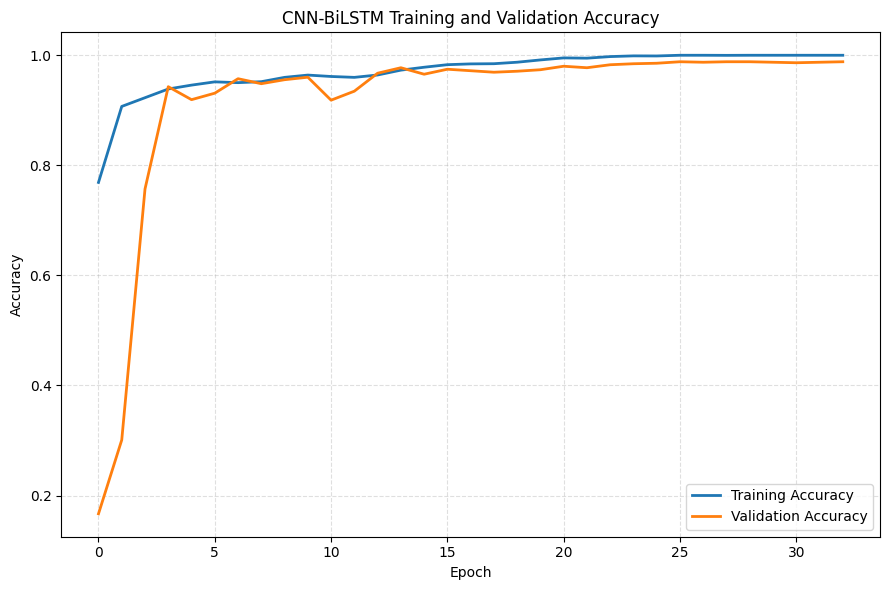

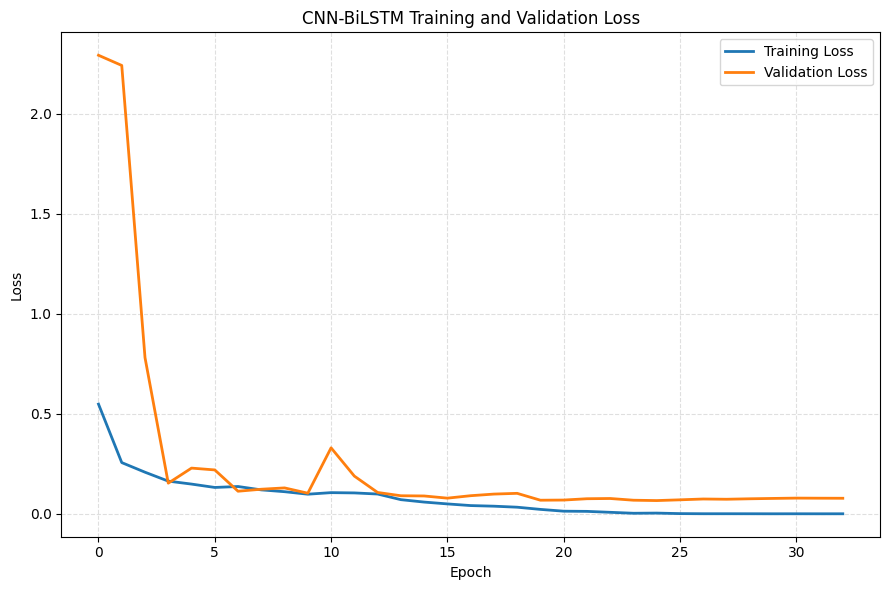


Evaluating the model on the independent test set...
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9199 - loss: 0.4659
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

CNN-BiLSTM TEST PERFORMANCE
test_loss: 0.4659
test_accuracy: 0.9199
test_precision_macro: 0.9188
test_recall_macro: 0.9173
test_f1_macro: 0.9175
test_precision_weighted: 0.9204
test_recall_weighted: 0.9199
test_f1_weighted: 0.9196
number_of_test_samples: 2947
number_of_classes: 6
original_label_range: 1-6
model_label_range: 0-5

Classification Report:
                    precision    recall  f1-score   support

           WALKING     0.9054    0.9073    0.9063       496
  WALKING_UPSTAIRS     0.9124    0.9066    0.9095       471
WALKING_DOWNSTAIRS     0.8791    0.8833    0.8812       420
           SITTING     0.9417    0.8554    0.8965       491
          STANDING     0.8924    0.9511    0.9208       532
            LAYING     0.9817    1.0000    0.9908       537

          accuracy                         0.9199      29

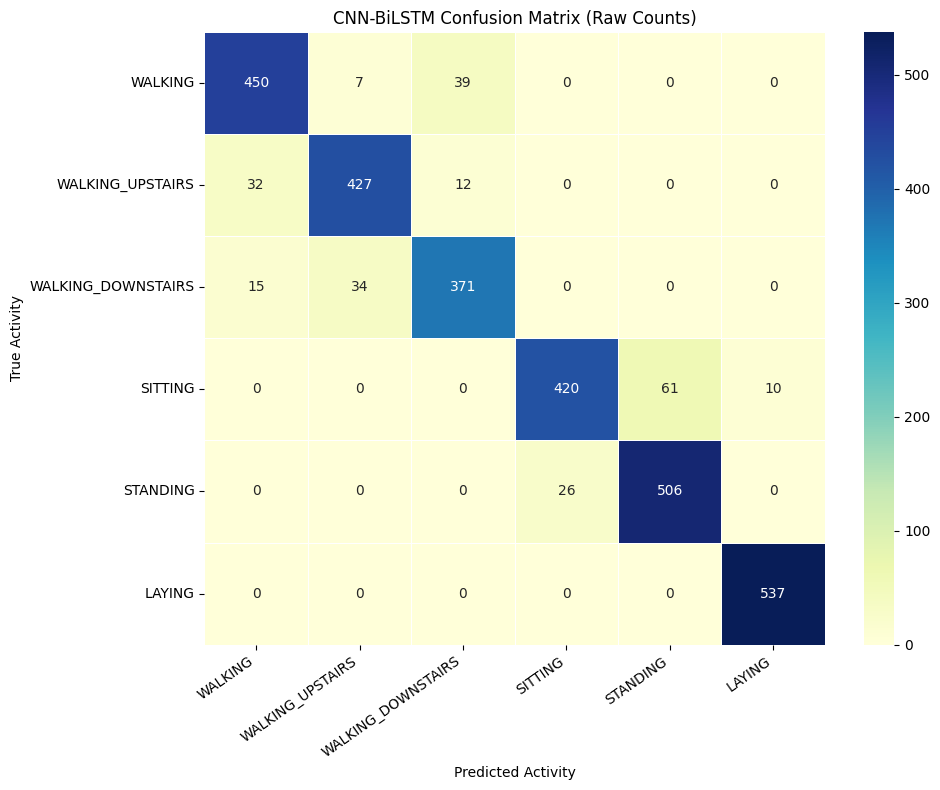


STEP 3 COMPLETED SUCCESSFULLY
Test Accuracy      : 0.9199
Macro Precision    : 0.9188
Macro Recall       : 0.9173
Macro F1-score     : 0.9175

All outputs saved to:
/content/drive/MyDrive/UCI/Step3_CNN_BiLSTM


In [2]:

# ============================================================
# STEP 3: CNN-BiLSTM MODEL DEVELOPMENT
# Dataset: UCI Human Activity Recognition (UCI-HAR)
# ============================================================

import os
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Conv1D,
    BatchNormalization,
    ReLU,
    MaxPooling1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001

DATA_PATH = r"/content/drive/MyDrive/UCI/Step2_Preprocessed"

OUTPUT_PATH = r"/content/drive/MyDrive/UCI/Step3_CNN_BiLSTM"
os.makedirs(OUTPUT_PATH, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("=" * 65)
print("STEP 3: CNN-BiLSTM MODEL DEVELOPMENT")
print("=" * 65)

# ------------------------------------------------------------
# 2. LOAD PREPROCESSED DATA
# ------------------------------------------------------------

X_train = np.load(os.path.join(DATA_PATH, "X_train.npy"))
y_train = np.load(os.path.join(DATA_PATH, "y_train.npy"))

X_val = np.load(os.path.join(DATA_PATH, "X_validation.npy"))
y_val = np.load(os.path.join(DATA_PATH, "y_validation.npy"))

X_test = np.load(os.path.join(DATA_PATH, "X_test.npy"))
y_test = np.load(os.path.join(DATA_PATH, "y_test.npy"))

print("\nOriginal array shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val  :", X_val.shape)
print("y_val  :", y_val.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

# ------------------------------------------------------------
# 3. DATA VALIDATION AND LABEL CORRECTION
# ------------------------------------------------------------

# Validate feature dimensions and finite values
assert X_train.ndim == 2
assert X_val.ndim == 2
assert X_test.ndim == 2

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all(), "Non-finite values in X_train"
assert np.isfinite(X_val).all(), "Non-finite values in X_val"
assert np.isfinite(X_test).all(), "Non-finite values in X_test"

# Original UCI-HAR labels are 1, 2, 3, 4, 5, 6.
# Sparse categorical cross-entropy requires 0, 1, 2, 3, 4, 5
# for a six-class output layer.
def convert_labels_to_zero_based(labels, split_name):
    labels = np.asarray(labels).reshape(-1)

    if not np.all(np.isfinite(labels)):
        raise ValueError(f"{split_name} contains non-finite labels.")

    if not np.all(labels == labels.astype(np.int32)):
        raise ValueError(f"{split_name} contains non-integer labels.")

    labels = labels.astype(np.int32)

    if not np.isin(labels, [1, 2, 3, 4, 5, 6]).all():
        raise ValueError(
            f"{split_name} must contain original UCI-HAR labels 1-6. "
            f"Found: {np.unique(labels)}"
        )

    return labels - 1


y_train = convert_labels_to_zero_based(y_train, "y_train")
y_val = convert_labels_to_zero_based(y_val, "y_validation")
y_test = convert_labels_to_zero_based(y_test, "y_test")

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\nCorrected labels:")
print("Training  :", np.unique(y_train))
print("Validation:", np.unique(y_val))
print("Testing   :", np.unique(y_test))
print("Label conversion successful: original 1-6 -> model labels 0-5")

# ------------------------------------------------------------
# 4. RESHAPE FEATURES FOR CNN-BiLSTM
# ------------------------------------------------------------

# IMPORTANT:
# This treats the 561 engineered features as a sequence.
# These are not the original 128-timestep raw sensor signals.

X_train_seq = X_train.astype(np.float32)[..., np.newaxis]
X_val_seq = X_val.astype(np.float32)[..., np.newaxis]
X_test_seq = X_test.astype(np.float32)[..., np.newaxis]

print("\nCNN-BiLSTM input shapes:")
print("Training  :", X_train_seq.shape)
print("Validation:", X_val_seq.shape)
print("Testing   :", X_test_seq.shape)

N_FEATURES = X_train_seq.shape[1]
N_CLASSES = 6

# ------------------------------------------------------------
# 5. BUILD CNN-BiLSTM MODEL
# ------------------------------------------------------------

inputs = Input(shape=(N_FEATURES, 1), name="input_features")

# CNN block 1
x = Conv1D(
    filters=32,
    kernel_size=3,
    padding="same",
    use_bias=True,
    name="conv1"
)(inputs)
x = BatchNormalization(name="bn1")(x)
x = ReLU(name="relu1")(x)
x = MaxPooling1D(pool_size=2, name="pool1")(x)

# CNN block 2
x = Conv1D(
    filters=64,
    kernel_size=3,
    padding="same",
    use_bias=True,
    name="conv2"
)(x)
x = BatchNormalization(name="bn2")(x)
x = ReLU(name="relu2")(x)
x = MaxPooling1D(pool_size=2, name="pool2")(x)

# CNN block 3
x = Conv1D(
    filters=128,
    kernel_size=3,
    padding="same",
    use_bias=True,
    name="conv3"
)(x)
x = BatchNormalization(name="bn3")(x)
x = ReLU(name="relu3")(x)

# Bidirectional LSTM
x = Bidirectional(
    LSTM(128, return_sequences=False),
    name="bilstm"
)(x)

# Fully connected layers
x = Dense(256, activation="relu", name="dense256")(x)
x = Dropout(0.3, name="dropout1")(x)

x = Dense(128, activation="relu", name="dense128")(x)
x = Dropout(0.3, name="dropout2")(x)

# Six activity classes; labels used by the model are 0-5
outputs = Dense(
    N_CLASSES,
    activation="softmax",
    name="activity_classification"
)(x)

model = Model(inputs=inputs, outputs=outputs, name="CNN_BiLSTM")

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nModel architecture:")
model.summary()

# Save architecture summary
with open(
    os.path.join(OUTPUT_PATH, "model_summary.txt"),
    "w",
    encoding="utf-8"
) as file:
    model.summary(print_fn=lambda line: file.write(line + "\n"))

# ------------------------------------------------------------
# 6. CALLBACKS
# ------------------------------------------------------------

best_model_path = os.path.join(
    OUTPUT_PATH, "best_cnn_bilstm.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# ------------------------------------------------------------
# 7. TRAIN MODEL
# ------------------------------------------------------------

print("\nStarting CNN-BiLSTM training...")

history = model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1,
    shuffle=True
)

# Save final model
final_model_path = os.path.join(
    OUTPUT_PATH, "final_cnn_bilstm.keras"
)
model.save(final_model_path)

print("\nTraining completed.")
print("Best model saved:", best_model_path)
print("Final model saved:", final_model_path)

# ------------------------------------------------------------
# 8. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))

history_csv = os.path.join(
    OUTPUT_PATH, "training_history.csv"
)
history_df.to_csv(history_csv, index=False)

# ------------------------------------------------------------
# 9. TRAINING AND VALIDATION ACCURACY GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN-BiLSTM Training and Validation Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "accuracy_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 10. TRAINING AND VALIDATION LOSS GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))
plt.plot(
    history.history["loss"],
    label="Training Loss",
    linewidth=2
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN-BiLSTM Training and Validation Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 11. TEST SET EVALUATION
# ------------------------------------------------------------

print("\nEvaluating the model on the independent test set...")

test_loss, test_accuracy = model.evaluate(
    X_test_seq,
    y_test,
    batch_size=BATCH_SIZE,
    verbose=1
)

probabilities = model.predict(
    X_test_seq,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Model class indices are 0-5
y_pred_zero_based = np.argmax(probabilities, axis=1)

# Convert both true and predicted labels to original UCI-HAR
# activity identifiers 1-6 for reporting.
y_test_original = y_test + 1
y_pred_original = y_pred_zero_based + 1

# ------------------------------------------------------------
# 12. CALCULATE PERFORMANCE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(y_test_original, y_pred_original)

precision_macro = precision_score(
    y_test_original,
    y_pred_original,
    labels=[1, 2, 3, 4, 5, 6],
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_test_original,
    y_pred_original,
    labels=[1, 2, 3, 4, 5, 6],
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_test_original,
    y_pred_original,
    labels=[1, 2, 3, 4, 5, 6],
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    y_test_original,
    y_pred_original,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_test_original,
    y_pred_original,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_test_original,
    y_pred_original,
    average="weighted",
    zero_division=0
)

metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(accuracy),
    "test_precision_macro": float(precision_macro),
    "test_recall_macro": float(recall_macro),
    "test_f1_macro": float(f1_macro),
    "test_precision_weighted": float(precision_weighted),
    "test_recall_weighted": float(recall_weighted),
    "test_f1_weighted": float(f1_weighted),
    "number_of_test_samples": int(len(y_test_original)),
    "number_of_classes": int(N_CLASSES),
    "original_label_range": "1-6",
    "model_label_range": "0-5"
}

print("\n" + "=" * 65)
print("CNN-BiLSTM TEST PERFORMANCE")
print("=" * 65)

for metric_name, metric_value in metrics.items():
    if isinstance(metric_value, float):
        print(f"{metric_name}: {metric_value:.4f}")
    else:
        print(f"{metric_name}: {metric_value}")

with open(
    os.path.join(OUTPUT_PATH, "test_metrics.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(metrics, file, indent=4)

pd.DataFrame([metrics]).to_csv(
    os.path.join(OUTPUT_PATH, "test_metrics.csv"),
    index=False
)

# ------------------------------------------------------------
# 13. CLASSIFICATION REPORT
# ------------------------------------------------------------

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

report = classification_report(
    y_test_original,
    y_pred_original,
    labels=[1, 2, 3, 4, 5, 6],
    target_names=activity_names,
    digits=4,
    zero_division=0
)

print("\nClassification Report:")
print(report)

with open(
    os.path.join(OUTPUT_PATH, "classification_report.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

report_dict = classification_report(
    y_test_original,
    y_pred_original,
    labels=[1, 2, 3, 4, 5, 6],
    target_names=activity_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).transpose().to_csv(
    os.path.join(OUTPUT_PATH, "classification_report.csv")
)

# ------------------------------------------------------------
# 14. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_original,
    y_pred_original,
    labels=[1, 2, 3, 4, 5, 6]
)

cm_df = pd.DataFrame(
    cm,
    index=activity_names,
    columns=activity_names
)

cm_df.to_csv(
    os.path.join(OUTPUT_PATH, "confusion_matrix_counts.csv")
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=activity_names,
    yticklabels=activity_names,
    linewidths=0.5,
    cbar=True
)
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.title("CNN-BiLSTM Confusion Matrix (Raw Counts)")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 15. SAVE PREDICTIONS
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "true_label": y_test_original,
    "predicted_label": y_pred_original
})

# Save class probabilities with activity names
for class_index, activity_name in enumerate(activity_names):
    prediction_df[f"probability_{activity_name}"] = (
        probabilities[:, class_index]
    )

prediction_df.to_csv(
    os.path.join(OUTPUT_PATH, "test_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 16. SAVE EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

config = {
    "model": "CNN-BiLSTM",
    "dataset": "UCI-HAR engineered feature dataset",
    "input_features": int(N_FEATURES),
    "input_representation": "(samples, 561, 1)",
    "num_classes": int(N_CLASSES),
    "label_conversion": "Original labels 1-6 mapped to model labels 0-5",
    "batch_size": BATCH_SIZE,
    "maximum_epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "random_seed": SEED,
    "optimizer": "Adam",
    "loss": "sparse_categorical_crossentropy",
    "early_stopping_monitor": "val_loss",
    "early_stopping_patience": 8,
    "dropout": 0.3
}

with open(
    os.path.join(OUTPUT_PATH, "experiment_config.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, indent=4)

# ------------------------------------------------------------
# 17. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 65)

print(f"Test Accuracy      : {accuracy:.4f}")
print(f"Macro Precision    : {precision_macro:.4f}")
print(f"Macro Recall       : {recall_macro:.4f}")
print(f"Macro F1-score     : {f1_macro:.4f}")

print("\nAll outputs saved to:")
print(OUTPUT_PATH)

STEP 4: BAT OPTIMIZATION FOR CNN-BiLSTM
Data directory: /content/drive/MyDrive/UCI/Step2_Preprocessed
Output directory: /content/drive/MyDrive/UCI/Step4_Bat_Optimization

Data loaded:
Training: (6249, 561, 1) (6249,)
Validation: (1103, 561, 1) (1103,)
Testing: (2947, 561, 1) (2947,)
Model labels: [0 1 2 3 4 5]

Starting Bat Algorithm hyperparameter search...
Candidates in initial population: 4
Optimization iterations: 3
Candidate 01 | val_loss=0.26520 | val_accuracy=0.9012 | params={'learning_rate': 0.00353111691382141, 'dropout': 0.32555137590082095, 'filters': 64, 'lstm_units': 128, 'batch_size': 32}
Candidate 02 | val_loss=0.29875 | val_accuracy=0.8785 | params={'learning_rate': 0.008938089586343595, 'dropout': 0.4544558807961412, 'filters': 64, 'lstm_units': 32, 'batch_size': 32}
Candidate 03 | val_loss=0.10315 | val_accuracy=0.9619 | params={'learning_rate': 0.0005515641726960964, 'dropout': 0.5207059955394407, 'filters': 32, 'lstm_units': 128, 'batch_size': 32}
Candidate 04 | val

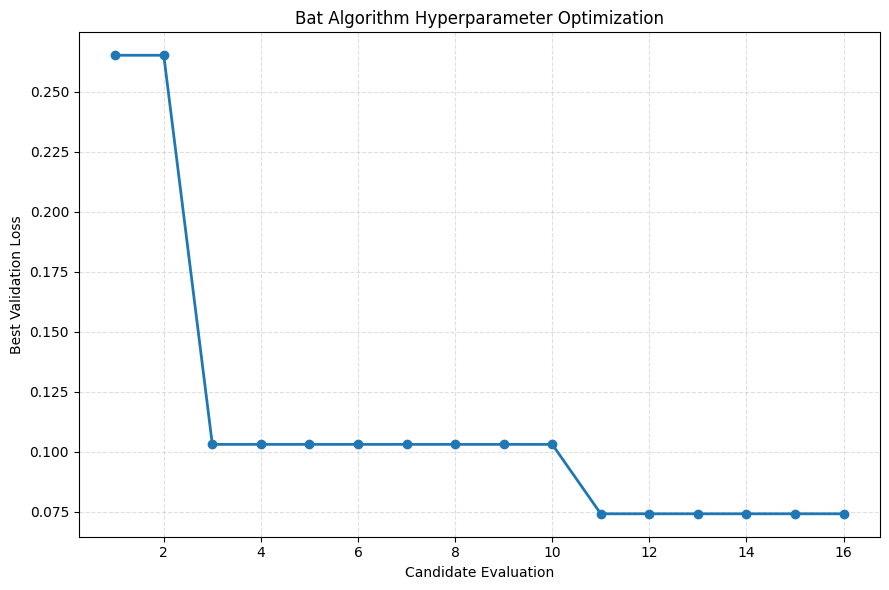


Training final CNN-BiLSTM with optimized hyperparameters...
Epoch 1/50
195/196 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5111 - loss: 1.1150
Epoch 1: val_loss improved from None to 2.61132, saving model to /content/drive/MyDrive/UCI/Step4_Bat_Optimization/best_bat_optimized_cnn_bilstm.keras

Epoch 1: finished saving model to /content/drive/MyDrive/UCI/Step4_Bat_Optimization/best_bat_optimized_cnn_bilstm.keras
196/196 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.6655 - loss: 0.7674 - val_accuracy: 0.1668 - val_loss: 2.6113 - learning_rate: 5.5156e-04
Epoch 2/50
195/196 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8767 - loss: 0.3313
Epoch 2: val_loss did not improve from 2.61132
196/196 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.8838 - loss: 0.3094 - val_accuracy: 0.1677 - val_loss: 3.8455 - learning_rate: 5.5156e-04
Epoch 3/50
195/196 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9238 - loss: 0.2091
Epoch 3: val_loss improved from 2.61132 to 0.56917, saving model to

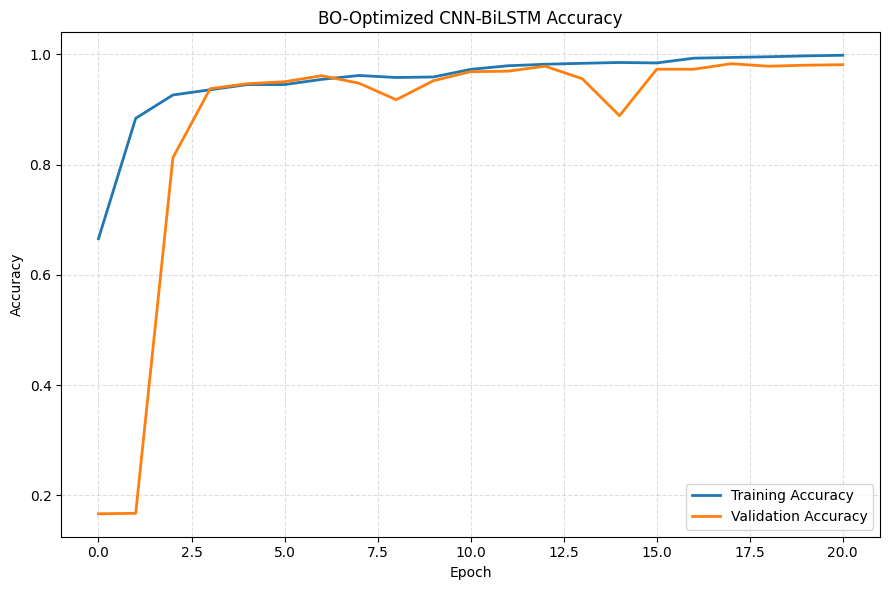

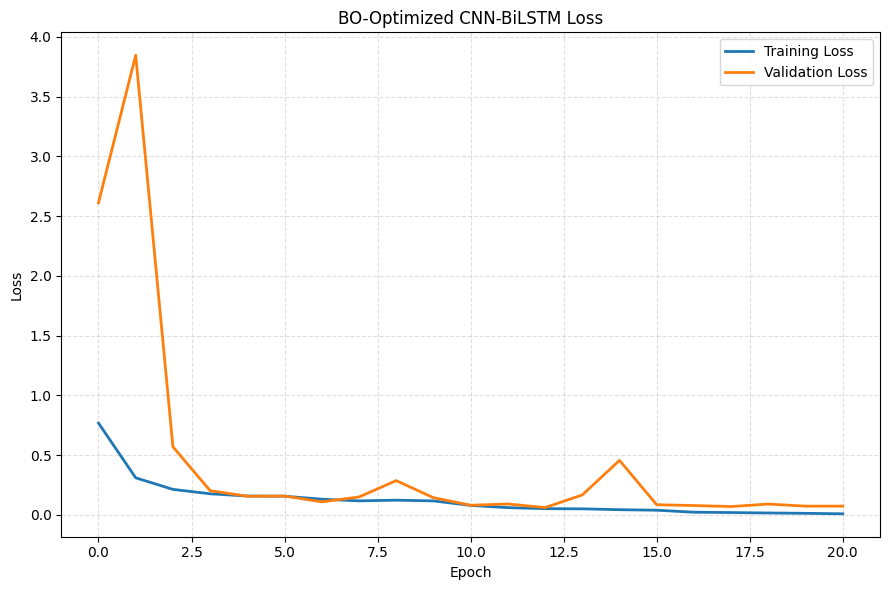


Evaluating optimized model on the independent test set...
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9097 - loss: 0.3886
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

BAT-OPTIMIZED CNN-BiLSTM TEST RESULTS
test_loss: 0.38859981298446655
test_accuracy: 0.9097387173396675
macro_precision: 0.9105454613693394
macro_recall: 0.9077503260533284
macro_f1: 0.9079496184157735
weighted_precision: 0.9119208663536683
weighted_recall: 0.9097387173396675
weighted_f1: 0.9096360908675882
test_samples: 2947
classes: 6
best_validation_loss_during_search: 0.07423153519630432
best_hyperparameters: {'learning_rate': 0.0005515641726960964, 'dropout': 0.5207059955394407, 'filters': 32, 'lstm_units': 128, 'batch_size': 32}

Classification Report:
                    precision    recall  f1-score   support

           WALKING     0.8736    0.9194    0.8959       496
  WALKING_UPSTAIRS     0.9341    0.8429    0.8862       471
WALKING_DOWNSTAIRS     0.8707    0.9143    0.8920       420
           SITTING     

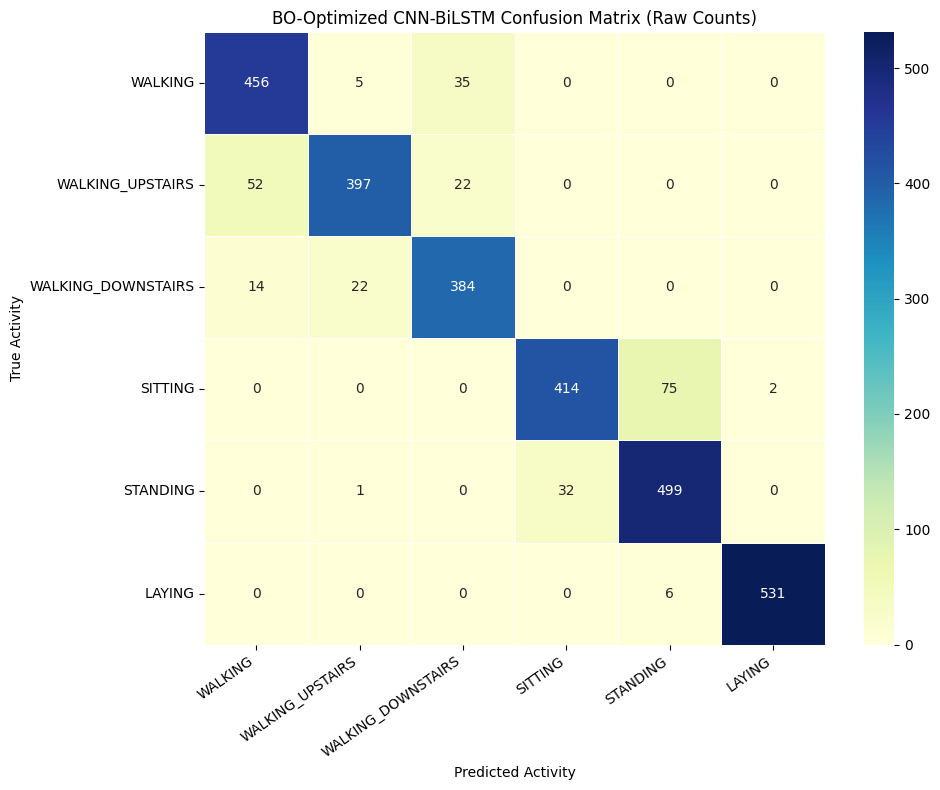


STEP 4 COMPLETED
Optimized hyperparameters:
{
    "learning_rate": 0.0005515641726960964,
    "dropout": 0.5207059955394407,
    "filters": 32,
    "lstm_units": 128,
    "batch_size": 32
}

Test accuracy : 0.9097
Macro F1      : 0.9079
Macro recall  : 0.9078

Saved outputs:
/content/drive/MyDrive/UCI/Step4_Bat_Optimization

Main output files:
- best_hyperparameters.json
- bat_search_history.csv
- bat_optimization_curve.png
- best_bat_optimized_cnn_bilstm.keras
- final_bat_optimized_cnn_bilstm.keras
- optimized_accuracy_curve.png
- optimized_loss_curve.png
- optimized_test_metrics.csv
- optimized_classification_report.txt
- optimized_confusion_matrix.png
- optimized_confusion_matrix_counts.csv
- optimized_test_predictions.csv


In [3]:

# ============================================================
# STEP 4: BAT OPTIMIZATION FOR CNN-BiLSTM
# BCSODL - Hyperparameter Optimization Component
# ============================================================

import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Input, Model
from tensorflow.keras.layers import (
    Conv1D, BatchNormalization, ReLU, MaxPooling1D,
    Bidirectional, LSTM, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Change this path if your Step 2 files are stored elsewhere.
DATA_PATH = r"/content/drive/MyDrive/UCI/Step2_Preprocessed"

# Windows alternative:
# DATA_PATH = r"G:\Work\5137\UCI-HAR Dataset\Step2_Preprocessed"

OUTPUT_PATH = os.path.join(
    os.path.dirname(DATA_PATH),
    "Step4_Bat_Optimization"
)
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Keep the search modest initially.
BAT_POPULATION = 4
BAT_ITERATIONS = 3
SEARCH_EPOCHS = 10
FINAL_EPOCHS = 50

N_CLASSES = 6
ACTIVITY_IDS = [1, 2, 3, 4, 5, 6]

ACTIVITY_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

print("=" * 70)
print("STEP 4: BAT OPTIMIZATION FOR CNN-BiLSTM")
print("=" * 70)
print("Data directory:", DATA_PATH)
print("Output directory:", OUTPUT_PATH)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

def load_array(filename):
    filepath = os.path.join(DATA_PATH, filename)
    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Missing file: {filepath}\n"
            "Check DATA_PATH and run Step 2 first."
        )
    return np.load(filepath)

X_train = load_array("X_train.npy").astype(np.float32)
y_train_raw = load_array("y_train.npy").reshape(-1)

X_val = load_array("X_validation.npy").astype(np.float32)
y_val_raw = load_array("y_validation.npy").reshape(-1)

X_test = load_array("X_test.npy").astype(np.float32)
y_test_raw = load_array("y_test.npy").reshape(-1)

# Convert original labels 1-6 to model labels 0-5.
# If labels are already 0-5, do not subtract again.
def normalize_labels(y, split_name):
    y = np.asarray(y).reshape(-1)

    if not np.all(np.isfinite(y)):
        raise ValueError(f"{split_name} contains invalid labels.")

    if not np.all(y == y.astype(np.int32)):
        raise ValueError(f"{split_name} contains non-integer labels.")

    y = y.astype(np.int32)
    unique = set(np.unique(y).tolist())

    if unique.issubset(set(range(1, 7))) and 0 not in unique:
        y = y - 1
    elif unique.issubset(set(range(0, 6))):
        pass
    else:
        raise ValueError(
            f"Unexpected labels in {split_name}: {sorted(unique)}"
        )

    if not set(np.unique(y).tolist()).issubset(set(range(6))):
        raise ValueError(f"Label conversion failed for {split_name}.")

    return y

y_train = normalize_labels(y_train_raw, "y_train")
y_val = normalize_labels(y_val_raw, "y_validation")
y_test = normalize_labels(y_test_raw, "y_test")

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

# CNN-BiLSTM input format
X_train_seq = X_train[..., np.newaxis]
X_val_seq = X_val[..., np.newaxis]
X_test_seq = X_test[..., np.newaxis]

N_FEATURES = X_train_seq.shape[1]

print("\nData loaded:")
print("Training:", X_train_seq.shape, y_train.shape)
print("Validation:", X_val_seq.shape, y_val.shape)
print("Testing:", X_test_seq.shape, y_test.shape)
print("Model labels:", np.unique(y_train))

# ------------------------------------------------------------
# 3. HYPERPARAMETER SEARCH SPACE
# ------------------------------------------------------------
# Each bat position has five normalized values in [0, 1].
#
# Dimension 0: learning rate, log scale
# Dimension 1: dropout
# Dimension 2: CNN filters
# Dimension 3: BiLSTM units
# Dimension 4: batch size

def decode_position(position):
    position = np.clip(position, 0.0, 1.0)

    learning_rate = 10 ** (
        -4 + position[0] * 2
    )  # 0.0001 to 0.01

    dropout = 0.15 + position[1] * 0.40  # 0.15 to 0.55

    filter_options = [16, 32, 64]
    filters = filter_options[
        min(int(position[2] * len(filter_options)), 2)
    ]

    lstm_options = [32, 64, 128]
    lstm_units = lstm_options[
        min(int(position[3] * len(lstm_options)), 2)
    ]

    batch_options = [32, 64]
    batch_size = batch_options[
        min(int(position[4] * len(batch_options)), 1)
    ]

    return {
        "learning_rate": float(learning_rate),
        "dropout": float(dropout),
        "filters": int(filters),
        "lstm_units": int(lstm_units),
        "batch_size": int(batch_size)
    }

# ------------------------------------------------------------
# 4. CNN-BiLSTM MODEL BUILDER
# ------------------------------------------------------------

def build_model(params):
    inputs = Input(shape=(N_FEATURES, 1), name="input_features")

    x = Conv1D(
        params["filters"], 3, padding="same",
        activation=None
    )(inputs)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(
        params["filters"] * 2, 3, padding="same",
        activation=None
    )(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = MaxPooling1D(pool_size=2)(x)

    x = Conv1D(
        params["filters"] * 4, 3, padding="same",
        activation=None
    )(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    x = Bidirectional(
        LSTM(params["lstm_units"])
    )(x)

    x = Dense(256, activation="relu")(x)
    x = Dropout(params["dropout"])(x)

    x = Dense(128, activation="relu")(x)
    x = Dropout(params["dropout"])(x)

    outputs = Dense(
        N_CLASSES, activation="softmax",
        name="activity_classification"
    )(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(
            learning_rate=params["learning_rate"]
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# ------------------------------------------------------------
# 5. FITNESS FUNCTION
# ------------------------------------------------------------
# Minimize the best validation loss.
# Test data is deliberately not used here.

evaluation_counter = 0

def evaluate_candidate(position):
    global evaluation_counter
    evaluation_counter += 1

    params = decode_position(position)

    # Ensure repeatable initialization for a given evaluation.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + evaluation_counter)

    model = build_model(params)

    history = model.fit(
        X_train_seq,
        y_train,
        validation_data=(X_val_seq, y_val),
        epochs=SEARCH_EPOCHS,
        batch_size=params["batch_size"],
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True,
                verbose=0
            )
        ],
        verbose=0,
        shuffle=True
    )

    best_val_loss = float(np.min(history.history["val_loss"]))
    best_val_accuracy = float(np.max(history.history["val_accuracy"]))

    record = {
        "evaluation": evaluation_counter,
        **params,
        "best_validation_loss": best_val_loss,
        "best_validation_accuracy": best_val_accuracy,
        "epochs_completed": len(history.history["loss"])
    }

    del model
    tf.keras.backend.clear_session()

    print(
        f"Candidate {evaluation_counter:02d} | "
        f"val_loss={best_val_loss:.5f} | "
        f"val_accuracy={best_val_accuracy:.4f} | "
        f"params={params}"
    )

    return best_val_loss, record

# ------------------------------------------------------------
# 6. BAT ALGORITHM
# ------------------------------------------------------------

def bat_optimization(population_size, iterations, dimensions=5):
    rng = np.random.default_rng(SEED)

    # Initial bat positions and velocities
    positions = rng.uniform(
        0.0, 1.0, size=(population_size, dimensions)
    )
    velocities = np.zeros_like(positions)

    # Bat Algorithm parameters
    frequency_min = 0.0
    frequency_max = 2.0
    loudness = np.full(population_size, 0.9)
    pulse_rate = np.full(population_size, 0.5)

    alpha = 0.9
    gamma = 0.9

    fitness = np.full(population_size, np.inf)
    records = []
    best_position = None
    best_fitness = np.inf

    # Evaluate initial population
    for i in range(population_size):
        fitness[i], record = evaluate_candidate(positions[i])
        record["iteration"] = 0
        record["bat"] = i + 1
        records.append(record)

        if fitness[i] < best_fitness:
            best_fitness = fitness[i]
            best_position = positions[i].copy()

    # Optimization loop
    for iteration in range(1, iterations + 1):
        print(f"\n--- Bat Optimization Iteration {iteration}/{iterations} ---")

        for i in range(population_size):
            frequency = rng.uniform(frequency_min, frequency_max)

            velocities[i] += (
                positions[i] - best_position
            ) * frequency

            candidate = positions[i] + velocities[i]

            # Local random walk around current best
            if rng.random() > pulse_rate[i]:
                candidate = (
                    best_position
                    + 0.05 * np.mean(loudness)
                    * rng.normal(size=dimensions)
                )

            candidate = np.clip(candidate, 0.0, 1.0)

            candidate_fitness, record = evaluate_candidate(candidate)

            # Accept candidate when improved and loudness condition passes
            if (
                candidate_fitness < fitness[i]
                and rng.random() < loudness[i]
            ):
                positions[i] = candidate
                fitness[i] = candidate_fitness

                loudness[i] *= alpha
                pulse_rate[i] *= (
                    1.0 - np.exp(-gamma * iteration)
                )

            if candidate_fitness < best_fitness:
                best_fitness = candidate_fitness
                best_position = candidate.copy()

            record["iteration"] = iteration
            record["bat"] = i + 1
            record["current_global_best_loss"] = float(best_fitness)
            records.append(record)

        print("Best validation loss so far:", round(best_fitness, 6))
        print("Best hyperparameters:", decode_position(best_position))

    return best_position, best_fitness, pd.DataFrame(records)

# ------------------------------------------------------------
# 7. RUN BAT SEARCH
# ------------------------------------------------------------

print("\nStarting Bat Algorithm hyperparameter search...")
print("Candidates in initial population:", BAT_POPULATION)
print("Optimization iterations:", BAT_ITERATIONS)

best_position, best_val_loss, search_df = bat_optimization(
    population_size=BAT_POPULATION,
    iterations=BAT_ITERATIONS
)

best_params = decode_position(best_position)

search_csv = os.path.join(
    OUTPUT_PATH, "bat_search_history.csv"
)
search_df.to_csv(search_csv, index=False)

with open(
    os.path.join(OUTPUT_PATH, "best_hyperparameters.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "best_validation_loss": float(best_val_loss),
            "best_hyperparameters": best_params,
            "population_size": BAT_POPULATION,
            "iterations": BAT_ITERATIONS,
            "search_epochs_per_candidate": SEARCH_EPOCHS,
            "random_seed": SEED
        },
        f,
        indent=4
    )

print("\nBest hyperparameters found:")
print(json.dumps(best_params, indent=4))
print("Best validation loss:", round(best_val_loss, 6))

# ------------------------------------------------------------
# 8. PLOT BAT OPTIMIZATION HISTORY
# ------------------------------------------------------------

# Each row is one candidate evaluation.
# Plot the best loss found up to each evaluation.
search_df["best_loss_so_far"] = (
    search_df["best_validation_loss"].cummin()
)

plt.figure(figsize=(9, 6))
plt.plot(
    search_df["evaluation"],
    search_df["best_loss_so_far"],
    marker="o",
    linewidth=2
)
plt.xlabel("Candidate Evaluation")
plt.ylabel("Best Validation Loss")
plt.title("Bat Algorithm Hyperparameter Optimization")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "bat_optimization_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 9. TRAIN FINAL OPTIMIZED CNN-BiLSTM
# ------------------------------------------------------------

print("\nTraining final CNN-BiLSTM with optimized hyperparameters...")

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

optimized_model = build_model(best_params)

best_model_path = os.path.join(
    OUTPUT_PATH, "best_bat_optimized_cnn_bilstm.keras"
)

final_history = optimized_model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=FINAL_EPOCHS,
    batch_size=best_params["batch_size"],
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        ),
        ModelCheckpoint(
            best_model_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ],
    verbose=1,
    shuffle=True
)

# Save the final in-memory model with restored best weights.
final_model_path = os.path.join(
    OUTPUT_PATH, "final_bat_optimized_cnn_bilstm.keras"
)
optimized_model.save(final_model_path)

# Save final training history
final_history_df = pd.DataFrame(final_history.history)
final_history_df.insert(
    0, "epoch", np.arange(1, len(final_history_df) + 1)
)
final_history_df.to_csv(
    os.path.join(OUTPUT_PATH, "final_training_history.csv"),
    index=False
)

# ------------------------------------------------------------
# 10. TRAINING CURVES
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))
plt.plot(
    final_history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)
plt.plot(
    final_history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("BO-Optimized CNN-BiLSTM Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "optimized_accuracy_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure(figsize=(9, 6))
plt.plot(
    final_history.history["loss"],
    label="Training Loss",
    linewidth=2
)
plt.plot(
    final_history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BO-Optimized CNN-BiLSTM Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "optimized_loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 11. FINAL INDEPENDENT TEST EVALUATION
# ------------------------------------------------------------

print("\nEvaluating optimized model on the independent test set...")

test_loss, test_accuracy = optimized_model.evaluate(
    X_test_seq,
    y_test,
    batch_size=best_params["batch_size"],
    verbose=1
)

probabilities = optimized_model.predict(
    X_test_seq,
    batch_size=best_params["batch_size"],
    verbose=1
)

# Model labels are 0-5.
y_pred = np.argmax(probabilities, axis=1)

# Convert true and predicted labels back to original IDs 1-6.
y_test_original = y_test + 1
y_pred_original = y_pred + 1

metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(
        accuracy_score(y_test_original, y_pred_original)
    ),
    "macro_precision": float(
        precision_score(
            y_test_original, y_pred_original,
            labels=ACTIVITY_IDS, average="macro",
            zero_division=0
        )
    ),
    "macro_recall": float(
        recall_score(
            y_test_original, y_pred_original,
            labels=ACTIVITY_IDS, average="macro",
            zero_division=0
        )
    ),
    "macro_f1": float(
        f1_score(
            y_test_original, y_pred_original,
            labels=ACTIVITY_IDS, average="macro",
            zero_division=0
        )
    ),
    "weighted_precision": float(
        precision_score(
            y_test_original, y_pred_original,
            average="weighted", zero_division=0
        )
    ),
    "weighted_recall": float(
        recall_score(
            y_test_original, y_pred_original,
            average="weighted", zero_division=0
        )
    ),
    "weighted_f1": float(
        f1_score(
            y_test_original, y_pred_original,
            average="weighted", zero_division=0
        )
    ),
    "test_samples": int(len(y_test_original)),
    "classes": 6,
    "best_validation_loss_during_search": float(best_val_loss),
    "best_hyperparameters": best_params
}

print("\n" + "=" * 70)
print("BAT-OPTIMIZED CNN-BiLSTM TEST RESULTS")
print("=" * 70)

for key, value in metrics.items():
    print(f"{key}: {value}")

with open(
    os.path.join(OUTPUT_PATH, "optimized_test_metrics.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame([metrics]).to_csv(
    os.path.join(OUTPUT_PATH, "optimized_test_metrics.csv"),
    index=False
)

# ------------------------------------------------------------
# 12. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_test_original,
    y_pred_original,
    labels=ACTIVITY_IDS,
    target_names=ACTIVITY_NAMES,
    digits=4,
    zero_division=0
)

print("\nClassification Report:")
print(report)

with open(
    os.path.join(OUTPUT_PATH, "optimized_classification_report.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

# ------------------------------------------------------------
# 13. RAW-COUNT CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_original,
    y_pred_original,
    labels=ACTIVITY_IDS
)

cm_df = pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
)
cm_df.to_csv(
    os.path.join(OUTPUT_PATH, "optimized_confusion_matrix_counts.csv")
)

plt.figure(figsize=(10, 8))
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=ACTIVITY_NAMES,
    yticklabels=ACTIVITY_NAMES,
    linewidths=0.5
)
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.title("BO-Optimized CNN-BiLSTM Confusion Matrix (Raw Counts)")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "optimized_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 14. SAVE PREDICTIONS AND PROBABILITIES
# ------------------------------------------------------------

pred_df = pd.DataFrame({
    "true_label": y_test_original,
    "predicted_label": y_pred_original
})

for i, name in enumerate(ACTIVITY_NAMES):
    pred_df[f"probability_{name}"] = probabilities[:, i]

pred_df.to_csv(
    os.path.join(OUTPUT_PATH, "optimized_test_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 15. COMPLETION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 4 COMPLETED")
print("=" * 70)
print("Optimized hyperparameters:")
print(json.dumps(best_params, indent=4))
print(f"\nTest accuracy : {metrics['test_accuracy']:.4f}")
print(f"Macro F1      : {metrics['macro_f1']:.4f}")
print(f"Macro recall  : {metrics['macro_recall']:.4f}")
print("\nSaved outputs:")
print(OUTPUT_PATH)
print("\nMain output files:")
print("- best_hyperparameters.json")
print("- bat_search_history.csv")
print("- bat_optimization_curve.png")
print("- best_bat_optimized_cnn_bilstm.keras")
print("- final_bat_optimized_cnn_bilstm.keras")
print("- optimized_accuracy_curve.png")
print("- optimized_loss_curve.png")
print("- optimized_test_metrics.csv")
print("- optimized_classification_report.txt")
print("- optimized_confusion_matrix.png")
print("- optimized_confusion_matrix_counts.csv")
print("- optimized_test_predictions.csv")


STEP 5: CHICKEN SWARM OPTIMIZATION
Training: (6249, 561, 1) (6249,)
Validation: (1103, 561, 1) (1103,)
Testing: (2947, 561, 1) (2947,)

Step 4 starting configuration:
{
    "learning_rate": 0.0005515641726960964,
    "dropout": 0.5207059955394407,
    "filters": 32,
    "lstm_units": 128,
    "batch_size": 32
}

Starting Chicken Swarm Optimization...
Evaluation 001 | val_loss=0.11739 | val_accuracy=0.9583 | params={'learning_rate': 0.0005515641726960964, 'dropout': 0.5207059955394407, 'filters': 32, 'lstm_units': 128, 'batch_size': 32}
Evaluation 002 | val_loss=0.41939 | val_accuracy=0.8495 | params={'learning_rate': 0.008938089586343595, 'dropout': 0.4544558807961412, 'filters': 64, 'lstm_units': 32, 'batch_size': 32}
Evaluation 003 | val_loss=0.12796 | val_accuracy=0.9610 | params={'learning_rate': 0.0005515641726960964, 'dropout': 0.5207059955394407, 'filters': 32, 'lstm_units': 128, 'batch_size': 32}
Evaluation 004 | val_loss=2.20640 | val_accuracy=0.1750 | params={'learning_rate':

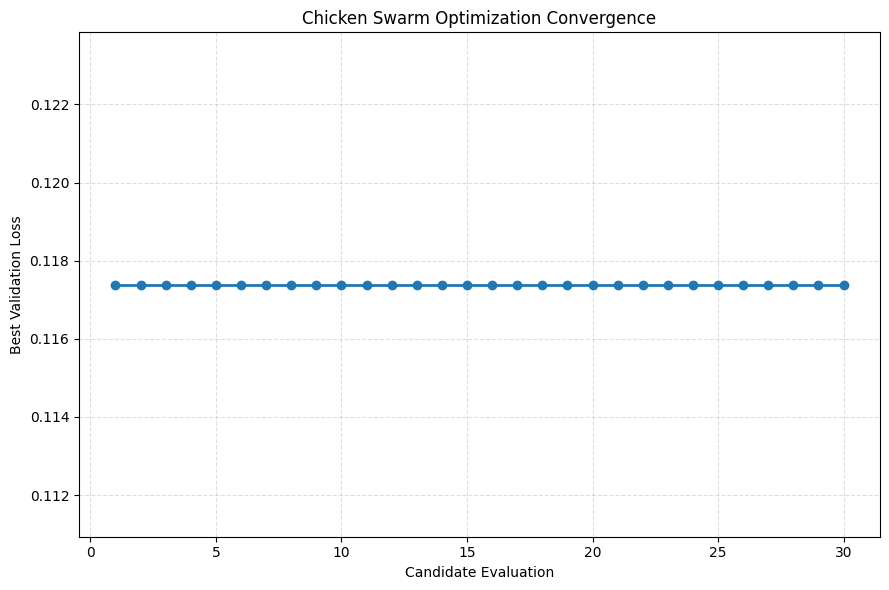


Training final CSO-optimized CNN-BiLSTM...
Epoch 1/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5143 - loss: 1.1106
Epoch 1: val_loss improved from None to 2.50875, saving model to /content/drive/MyDrive/UCI/Step5_Chicken_Swarm_Optimization/best_cso_optimized_cnn_bilstm.keras

Epoch 1: finished saving model to /content/drive/MyDrive/UCI/Step5_Chicken_Swarm_Optimization/best_cso_optimized_cnn_bilstm.keras
196/196 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.6702 - loss: 0.7608 - val_accuracy: 0.1668 - val_loss: 2.5088 - learning_rate: 5.5156e-04
Epoch 2/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8751 - loss: 0.3295
Epoch 2: val_loss did not improve from 2.50875
196/196 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.8913 - loss: 0.2958 - val_accuracy: 0.1732 - val_loss: 3.8188 - learning_rate: 5.5156e-04
Epoch 3/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9245 - loss: 0.2127
Epoch 3: val_loss improved from 2.50875 to 0.99556, saving model

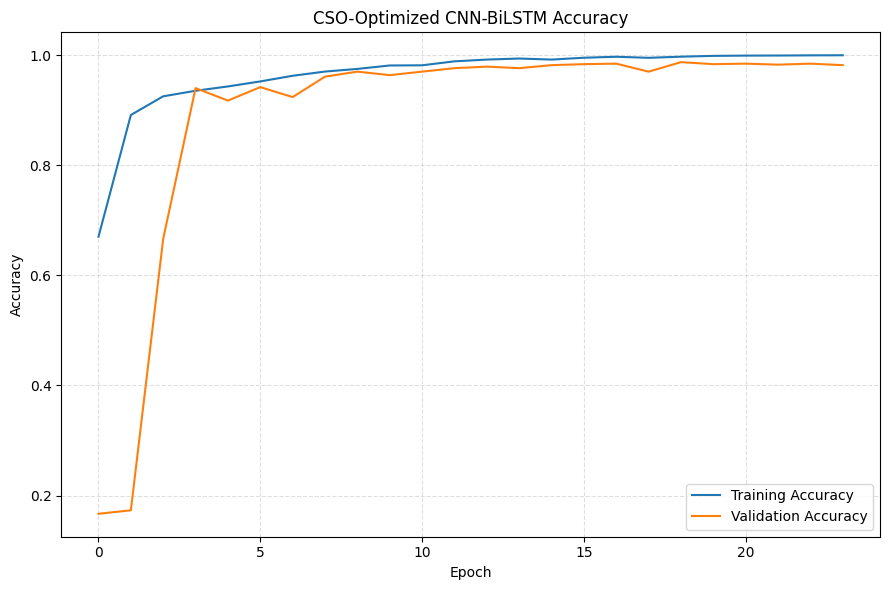

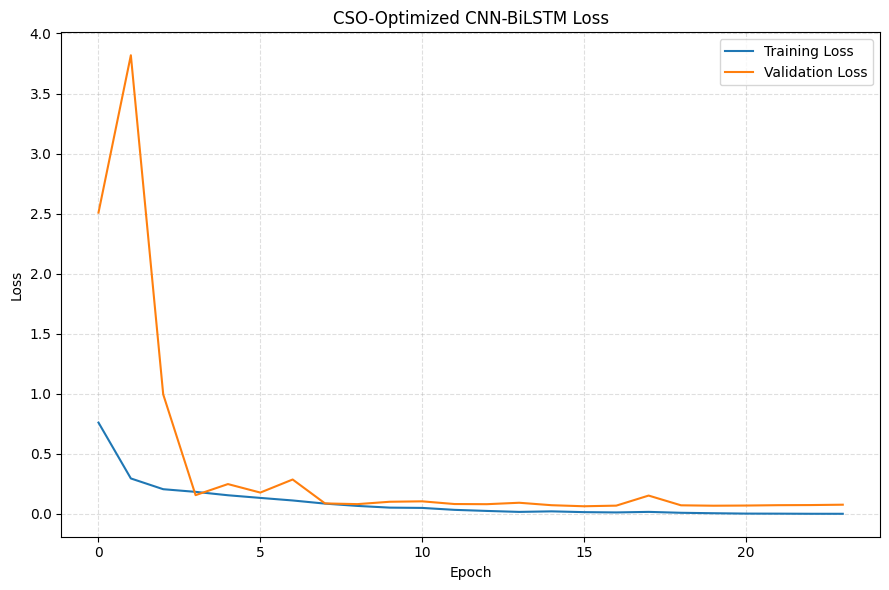


Final independent test evaluation...
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9192 - loss: 0.4173
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

CSO-Optimized Test Metrics
test_loss: 0.41731369495391846
test_accuracy: 0.9192399049881235
macro_precision: 0.9219422600756108
macro_recall: 0.9164514455930873
macro_f1: 0.9175920972720989
weighted_precision: 0.9220457233131705
weighted_recall: 0.9192399049881235
weighted_f1: 0.9190444746780706
test_samples: 2947
best_validation_loss: 0.1173902079463005
best_hyperparameters: {'learning_rate': 0.0005515641726960964, 'dropout': 0.5207059955394407, 'filters': 32, 'lstm_units': 128, 'batch_size': 32}

Classification Report:
                    precision    recall  f1-score   support

           WALKING     0.8404    0.9556    0.8943       496
  WALKING_UPSTAIRS     0.9264    0.8280    0.8744       471
WALKING_DOWNSTAIRS     0.9380    0.9000    0.9186       420
           SITTING     0.9446    0.8676    0.9045       491
          STANDING   

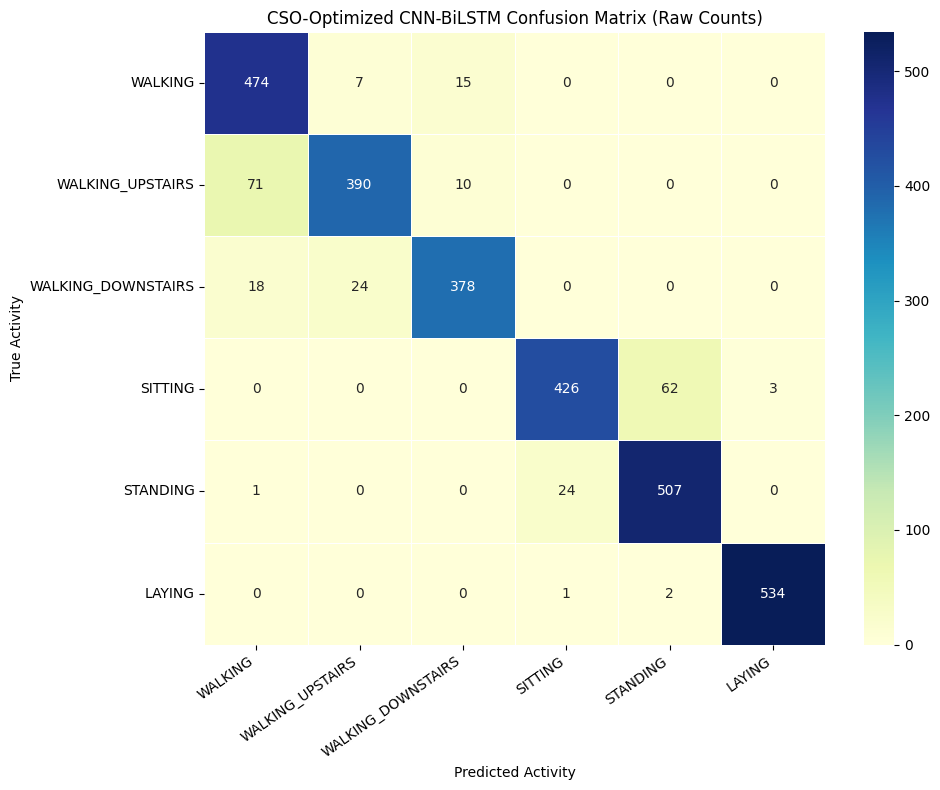


STEP 5 COMPLETED
Test Accuracy: 0.9192
Macro F1:      0.9176
Macro Recall:  0.9165

Output directory: /content/drive/MyDrive/UCI/Step5_Chicken_Swarm_Optimization

CSO outputs saved successfully.


In [4]:

# ============================================================
# STEP 5: CHICKEN SWARM OPTIMIZATION (CSO)
# BCSODL: CSO-based CNN-BiLSTM parameter optimization
# ============================================================

import os
import json
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras import Input, Model
from tensorflow.keras.layers import (
    Conv1D, BatchNormalization, ReLU, MaxPooling1D,
    Bidirectional, LSTM, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_PATH = "/content/drive/MyDrive/UCI/Step2_Preprocessed"
STEP4_PATH = "/content/drive/MyDrive/UCI/Step4_Bat_Optimization"
OUTPUT_PATH = "/content/drive/MyDrive/UCI/Step5_Chicken_Swarm_Optimization"

os.makedirs(OUTPUT_PATH, exist_ok=True)

# CSO search budget
POPULATION_SIZE = 6
MAX_ITERATIONS = 4
SEARCH_EPOCHS = 8
FINAL_EPOCHS = 50

N_CLASSES = 6
ACTIVITY_IDS = [1, 2, 3, 4, 5, 6]

ACTIVITY_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

print("=" * 70)
print("STEP 5: CHICKEN SWARM OPTIMIZATION")
print("=" * 70)

# ------------------------------------------------------------
# 2. LOAD AND VALIDATE DATA
# ------------------------------------------------------------

def load_array(filename):
    path = os.path.join(DATA_PATH, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Required file not found: {path}")
    return np.load(path)

X_train = load_array("X_train.npy").astype(np.float32)
y_train = load_array("y_train.npy").reshape(-1)

X_val = load_array("X_validation.npy").astype(np.float32)
y_val = load_array("y_validation.npy").reshape(-1)

X_test = load_array("X_test.npy").astype(np.float32)
y_test = load_array("y_test.npy").reshape(-1)

def to_zero_based(y, name):
    y = np.asarray(y).reshape(-1).astype(np.int32)
    unique = set(np.unique(y).tolist())

    if unique.issubset(set(range(1, 7))) and 0 not in unique:
        y = y - 1
    elif unique.issubset(set(range(0, 6))):
        pass
    else:
        raise ValueError(f"Unexpected labels in {name}: {sorted(unique)}")

    return y

y_train = to_zero_based(y_train, "y_train")
y_val = to_zero_based(y_val, "y_validation")
y_test = to_zero_based(y_test, "y_test")

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

X_train_seq = X_train[..., np.newaxis]
X_val_seq = X_val[..., np.newaxis]
X_test_seq = X_test[..., np.newaxis]

N_FEATURES = X_train_seq.shape[1]

print("Training:", X_train_seq.shape, y_train.shape)
print("Validation:", X_val_seq.shape, y_val.shape)
print("Testing:", X_test_seq.shape, y_test.shape)

# ------------------------------------------------------------
# 3. LOAD BEST STEP 4 HYPERPARAMETERS
# ------------------------------------------------------------

params_file = os.path.join(
    STEP4_PATH, "best_hyperparameters.json"
)

if os.path.isfile(params_file):
    with open(params_file, "r", encoding="utf-8") as f:
        step4_result = json.load(f)

    base_params = step4_result.get(
        "best_hyperparameters", step4_result
    )
else:
    print("Warning: Step 4 hyperparameter file not found.")
    print("Using fallback hyperparameters.")
    base_params = {
        "learning_rate": 0.00055,
        "dropout": 0.52,
        "filters": 32,
        "lstm_units": 128,
        "batch_size": 32
    }

print("\nStep 4 starting configuration:")
print(json.dumps(base_params, indent=4))

# ------------------------------------------------------------
# 4. DEFINE THE CSO SEARCH SPACE
# ------------------------------------------------------------
# The CSO candidate represents a vector of hyperparameters.
# CSO does not directly optimize every neural-network weight here.
# It searches learning rate, dropout, CNN filters, LSTM units,
# and batch size using validation loss as the fitness function.

def decode_position(position):
    position = np.clip(position, 0.0, 1.0)

    learning_rate = 10 ** (-4 + 2 * position[0])
    dropout = 0.15 + 0.40 * position[1]

    filter_options = [16, 32, 64]
    filters = filter_options[
        min(int(position[2] * 3), 2)
    ]

    lstm_options = [32, 64, 128]
    lstm_units = lstm_options[
        min(int(position[3] * 3), 2)
    ]

    batch_options = [32, 64]
    batch_size = batch_options[
        min(int(position[4] * 2), 1)
    ]

    return {
        "learning_rate": float(learning_rate),
        "dropout": float(dropout),
        "filters": int(filters),
        "lstm_units": int(lstm_units),
        "batch_size": int(batch_size)
    }

def encode_params(params):
    # Map the Step 4 configuration to a normalized search vector.
    lr = np.log10(params["learning_rate"])
    lr_position = (lr + 4.0) / 2.0

    dropout_position = (
        params["dropout"] - 0.15
    ) / 0.40

    filter_map = {16: 0.0, 32: 1.0 / 3.0, 64: 2.0 / 3.0}
    lstm_map = {32: 0.0, 64: 1.0 / 3.0, 128: 2.0 / 3.0}
    batch_map = {32: 0.0, 64: 0.5}

    return np.clip(np.array([
        lr_position,
        dropout_position,
        filter_map.get(params["filters"], 1.0 / 3.0),
        lstm_map.get(params["lstm_units"], 2.0 / 3.0),
        batch_map.get(params["batch_size"], 0.0)
    ], dtype=float), 0.0, 1.0)

# ------------------------------------------------------------
# 5. CNN-BiLSTM MODEL
# ------------------------------------------------------------

def build_model(params):
    inputs = Input(shape=(N_FEATURES, 1))

    x = Conv1D(
        params["filters"], 3, padding="same"
    )(inputs)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = MaxPooling1D(2)(x)

    x = Conv1D(
        params["filters"] * 2, 3, padding="same"
    )(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)
    x = MaxPooling1D(2)(x)

    x = Conv1D(
        params["filters"] * 4, 3, padding="same"
    )(x)
    x = BatchNormalization()(x)
    x = ReLU()(x)

    x = Bidirectional(
        LSTM(params["lstm_units"])
    )(x)

    x = Dense(256, activation="relu")(x)
    x = Dropout(params["dropout"])(x)

    x = Dense(128, activation="relu")(x)
    x = Dropout(params["dropout"])(x)

    outputs = Dense(N_CLASSES, activation="softmax")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=params["learning_rate"]),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ------------------------------------------------------------
# 6. FITNESS FUNCTION
# ------------------------------------------------------------

evaluation_count = 0

def fitness_function(position):
    global evaluation_count
    evaluation_count += 1

    params = decode_position(position)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + evaluation_count)

    model = build_model(params)

    history = model.fit(
        X_train_seq,
        y_train,
        validation_data=(X_val_seq, y_val),
        epochs=SEARCH_EPOCHS,
        batch_size=params["batch_size"],
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True,
                verbose=0
            )
        ],
        verbose=0,
        shuffle=True
    )

    best_loss = float(np.min(history.history["val_loss"]))
    best_accuracy = float(np.max(history.history["val_accuracy"]))

    record = {
        "evaluation": evaluation_count,
        **params,
        "validation_loss": best_loss,
        "validation_accuracy": best_accuracy,
        "epochs_completed": len(history.history["loss"])
    }

    del model
    tf.keras.backend.clear_session()

    print(
        f"Evaluation {evaluation_count:03d} | "
        f"val_loss={best_loss:.5f} | "
        f"val_accuracy={best_accuracy:.4f} | "
        f"params={params}"
    )

    return best_loss, record

# ------------------------------------------------------------
# 7. CHICKEN SWARM OPTIMIZATION
# ------------------------------------------------------------
# Roles:
# Roosters: strongest current candidates (low fitness)
# Hens: move relative to their assigned rooster and a peer
# Chicks: follow their assigned mother hen
#
# This is a documented, simplified CSO variant for reproducibility.
# Population roles and update rules are explicit below.

def run_cso(population_size, iterations, dimensions=5):
    rng = np.random.default_rng(SEED)

    positions = rng.uniform(
        0.0, 1.0, (population_size, dimensions)
    )

    # Seed the first candidate using Step 4's best configuration.
    positions[0] = encode_params(base_params)

    fitness_values = np.full(population_size, np.inf)
    records = []

    best_position = positions[0].copy()
    best_fitness = np.inf

    # Initial evaluation
    for i in range(population_size):
        fitness_values[i], rec = fitness_function(positions[i])
        rec["iteration"] = 0
        rec["candidate"] = i + 1
        records.append(rec)

        if fitness_values[i] < best_fitness:
            best_fitness = fitness_values[i]
            best_position = positions[i].copy()

    # CSO role proportions
    rooster_count = max(1, int(round(population_size * 0.2)))
    hen_count = max(1, int(round(population_size * 0.6)))
    chick_count = population_size - rooster_count - hen_count

    for iteration in range(1, iterations + 1):
        print(f"\n--- CSO Iteration {iteration}/{iterations} ---")

        # Rank candidates by fitness; lower validation loss is better.
        ranked = np.argsort(fitness_values)
        roosters = ranked[:rooster_count]
        remaining = ranked[rooster_count:]

        # Select hens from the remaining population.
        current_hen_count = min(hen_count, len(remaining))
        hens = remaining[:current_hen_count]
        chicks = remaining[current_hen_count:]

        new_positions = positions.copy()

        # Each hen is associated with a rooster.
        for idx, hen_idx in enumerate(hens):
            rooster_idx = roosters[idx % len(roosters)]
            peer_idx = rng.integers(0, population_size)

            r1 = rng.normal(0, 0.15)
            r2 = rng.normal(0, 0.10)

            new_positions[hen_idx] = (
                positions[hen_idx]
                + r1 * (
                    positions[rooster_idx] - positions[hen_idx]
                )
                + r2 * (
                    positions[peer_idx] - positions[hen_idx]
                )
            )

        # Chicks follow the current best rooster/mother proxy.
        for idx, chick_idx in enumerate(chicks):
            mother_idx = hens[idx % len(hens)] if len(hens) else roosters[0]
            follow_factor = rng.uniform(0.2, 0.8)

            new_positions[chick_idx] = (
                positions[chick_idx]
                + follow_factor * (
                    positions[mother_idx] - positions[chick_idx]
                )
            )

        # Roosters explore locally with a fitness-dependent perturbation.
        for rooster_idx in roosters:
            perturbation = rng.normal(
                0, 0.10, size=dimensions
            )
            new_positions[rooster_idx] = (
                positions[rooster_idx] + perturbation
            )

        new_positions = np.clip(new_positions, 0.0, 1.0)

        # Evaluate updated population and keep the better candidate
        # for each population member (elitist selection).
        for i in range(population_size):
            candidate_loss, rec = fitness_function(new_positions[i])

            if candidate_loss < fitness_values[i]:
                positions[i] = new_positions[i].copy()
                fitness_values[i] = candidate_loss

            if candidate_loss < best_fitness:
                best_fitness = candidate_loss
                best_position = new_positions[i].copy()

            rec["iteration"] = iteration
            rec["candidate"] = i + 1
            rec["best_validation_loss_so_far"] = float(best_fitness)
            records.append(rec)

        print("Best validation loss:", round(best_fitness, 6))
        print("Best configuration:", decode_position(best_position))

    return best_position, best_fitness, pd.DataFrame(records)

# ------------------------------------------------------------
# 8. RUN CSO
# ------------------------------------------------------------

print("\nStarting Chicken Swarm Optimization...")
best_position, best_validation_loss, cso_history = run_cso(
    population_size=POPULATION_SIZE,
    iterations=MAX_ITERATIONS
)

best_params = decode_position(best_position)

cso_history.to_csv(
    os.path.join(OUTPUT_PATH, "cso_search_history.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_PATH, "best_cso_hyperparameters.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump({
        "best_validation_loss": float(best_validation_loss),
        "best_hyperparameters": best_params,
        "population_size": POPULATION_SIZE,
        "iterations": MAX_ITERATIONS,
        "search_epochs": SEARCH_EPOCHS,
        "seed": SEED
    }, f, indent=4)

print("\nBest CSO hyperparameters:")
print(json.dumps(best_params, indent=4))
print("Best validation loss:", best_validation_loss)

# ------------------------------------------------------------
# 9. CSO CONVERGENCE CURVE
# ------------------------------------------------------------

cso_history["best_loss_so_far"] = (
    cso_history["validation_loss"].cummin()
)

plt.figure(figsize=(9, 6))
plt.plot(
    cso_history["evaluation"],
    cso_history["best_loss_so_far"],
    marker="o",
    linewidth=2
)
plt.xlabel("Candidate Evaluation")
plt.ylabel("Best Validation Loss")
plt.title("Chicken Swarm Optimization Convergence")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "cso_convergence_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 10. TRAIN FINAL CSO-OPTIMIZED MODEL
# ------------------------------------------------------------

print("\nTraining final CSO-optimized CNN-BiLSTM...")

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

optimized_model = build_model(best_params)

best_model_path = os.path.join(
    OUTPUT_PATH, "best_cso_optimized_cnn_bilstm.keras"
)

final_history = optimized_model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=FINAL_EPOCHS,
    batch_size=best_params["batch_size"],
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        ),
        ModelCheckpoint(
            best_model_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        )
    ],
    verbose=1,
    shuffle=True
)

final_model_path = os.path.join(
    OUTPUT_PATH, "final_cso_optimized_cnn_bilstm.keras"
)
optimized_model.save(final_model_path)

pd.DataFrame(final_history.history).to_csv(
    os.path.join(OUTPUT_PATH, "final_training_history.csv"),
    index=False
)

# ------------------------------------------------------------
# 11. TRAINING CURVES
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))
plt.plot(final_history.history["accuracy"], label="Training Accuracy")
plt.plot(final_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CSO-Optimized CNN-BiLSTM Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "cso_accuracy_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

plt.figure(figsize=(9, 6))
plt.plot(final_history.history["loss"], label="Training Loss")
plt.plot(final_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CSO-Optimized CNN-BiLSTM Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "cso_loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 12. FINAL TEST EVALUATION
# ------------------------------------------------------------

print("\nFinal independent test evaluation...")

test_loss, keras_test_accuracy = optimized_model.evaluate(
    X_test_seq,
    y_test,
    batch_size=best_params["batch_size"],
    verbose=1
)

probabilities = optimized_model.predict(
    X_test_seq,
    batch_size=best_params["batch_size"],
    verbose=1
)

y_pred_zero_based = np.argmax(probabilities, axis=1)
y_test_original = y_test + 1
y_pred_original = y_pred_zero_based + 1

metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(
        accuracy_score(y_test_original, y_pred_original)
    ),
    "macro_precision": float(
        precision_score(
            y_test_original, y_pred_original,
            labels=ACTIVITY_IDS, average="macro",
            zero_division=0
        )
    ),
    "macro_recall": float(
        recall_score(
            y_test_original, y_pred_original,
            labels=ACTIVITY_IDS, average="macro",
            zero_division=0
        )
    ),
    "macro_f1": float(
        f1_score(
            y_test_original, y_pred_original,
            labels=ACTIVITY_IDS, average="macro",
            zero_division=0
        )
    ),
    "weighted_precision": float(
        precision_score(
            y_test_original, y_pred_original,
            average="weighted", zero_division=0
        )
    ),
    "weighted_recall": float(
        recall_score(
            y_test_original, y_pred_original,
            average="weighted", zero_division=0
        )
    ),
    "weighted_f1": float(
        f1_score(
            y_test_original, y_pred_original,
            average="weighted", zero_division=0
        )
    ),
    "test_samples": int(len(y_test_original)),
    "best_validation_loss": float(best_validation_loss),
    "best_hyperparameters": best_params
}

print("\nCSO-Optimized Test Metrics")
for key, value in metrics.items():
    print(f"{key}: {value}")

with open(
    os.path.join(OUTPUT_PATH, "cso_test_metrics.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame([metrics]).to_csv(
    os.path.join(OUTPUT_PATH, "cso_test_metrics.csv"),
    index=False
)

# ------------------------------------------------------------
# 13. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    y_test_original,
    y_pred_original,
    labels=ACTIVITY_IDS,
    target_names=ACTIVITY_NAMES,
    digits=4,
    zero_division=0
)

print("\nClassification Report:")
print(report)

with open(
    os.path.join(OUTPUT_PATH, "cso_classification_report.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

# ------------------------------------------------------------
# 14. CONFUSION MATRIX (RAW COUNTS)
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test_original,
    y_pred_original,
    labels=ACTIVITY_IDS
)

pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    os.path.join(OUTPUT_PATH, "cso_confusion_matrix_counts.csv")
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=ACTIVITY_NAMES,
    yticklabels=ACTIVITY_NAMES,
    linewidths=0.5
)
plt.xlabel("Predicted Activity")
plt.ylabel("True Activity")
plt.title("CSO-Optimized CNN-BiLSTM Confusion Matrix (Raw Counts)")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_PATH, "cso_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 15. SAVE PREDICTIONS
# ------------------------------------------------------------

pred_df = pd.DataFrame({
    "true_label": y_test_original,
    "predicted_label": y_pred_original
})

for i, name in enumerate(ACTIVITY_NAMES):
    pred_df[f"probability_{name}"] = probabilities[:, i]

pred_df.to_csv(
    os.path.join(OUTPUT_PATH, "cso_test_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 16. COMPLETION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 5 COMPLETED")
print("=" * 70)
print(f"Test Accuracy: {metrics['test_accuracy']:.4f}")
print(f"Macro F1:      {metrics['macro_f1']:.4f}")
print(f"Macro Recall:  {metrics['macro_recall']:.4f}")
print("\nOutput directory:", OUTPUT_PATH)
print("\nCSO outputs saved successfully.")


STEP 6: BCSODL INTEGRATION AND COMPARATIVE EVALUATION
Test features: (2947, 561, 1)
Test labels: (2947,)
Model label IDs: [0 1 2 3 4 5]

Evaluating: CNN-BiLSTM Baseline
Model                 CNN-BiLSTM Baseline
Accuracy                         0.919919
Macro_Precision                  0.918802
Macro_Recall                     0.917283
Macro_F1                         0.917525
Weighted_Precision               0.920393
Weighted_Recall                  0.919919
Weighted_F1                      0.919624

Evaluating: Bat-Optimized CNN-BiLSTM
Model                 Bat-Optimized CNN-BiLSTM
Accuracy                              0.909739
Macro_Precision                       0.910545
Macro_Recall                           0.90775
Macro_F1                               0.90795
Weighted_Precision                    0.911921
Weighted_Recall                       0.909739
Weighted_F1                           0.909636

Evaluating: CSO-Optimized CNN-BiLSTM
Model                 CSO-Optimized CNN-BiL

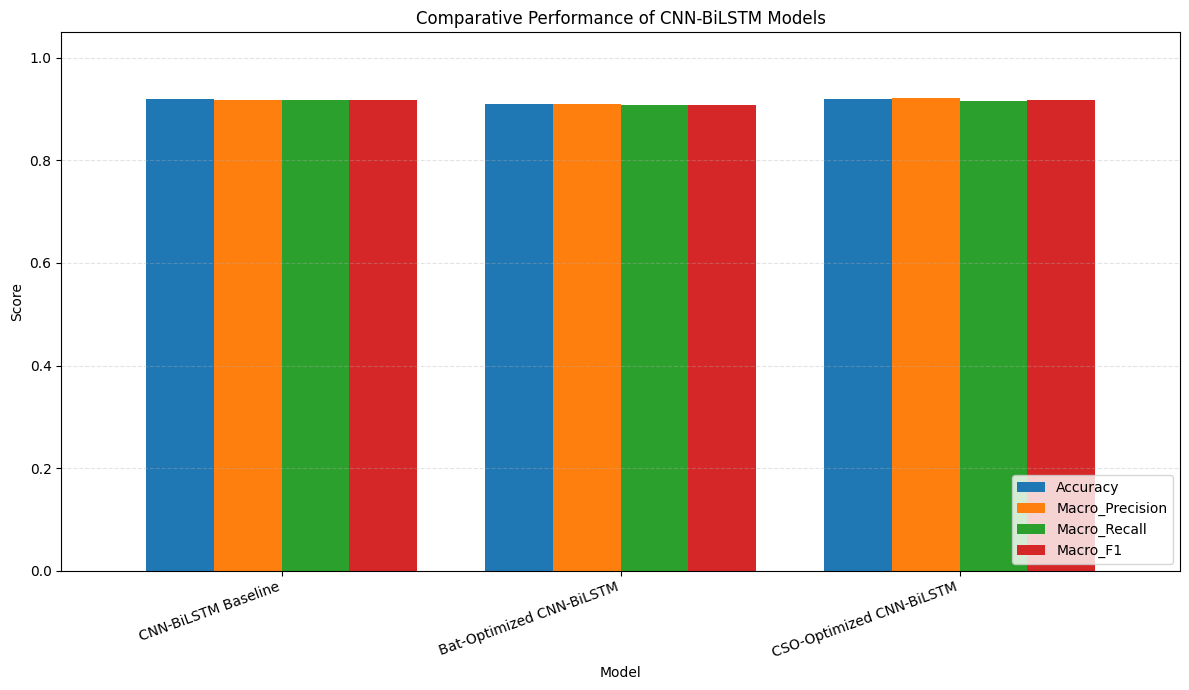

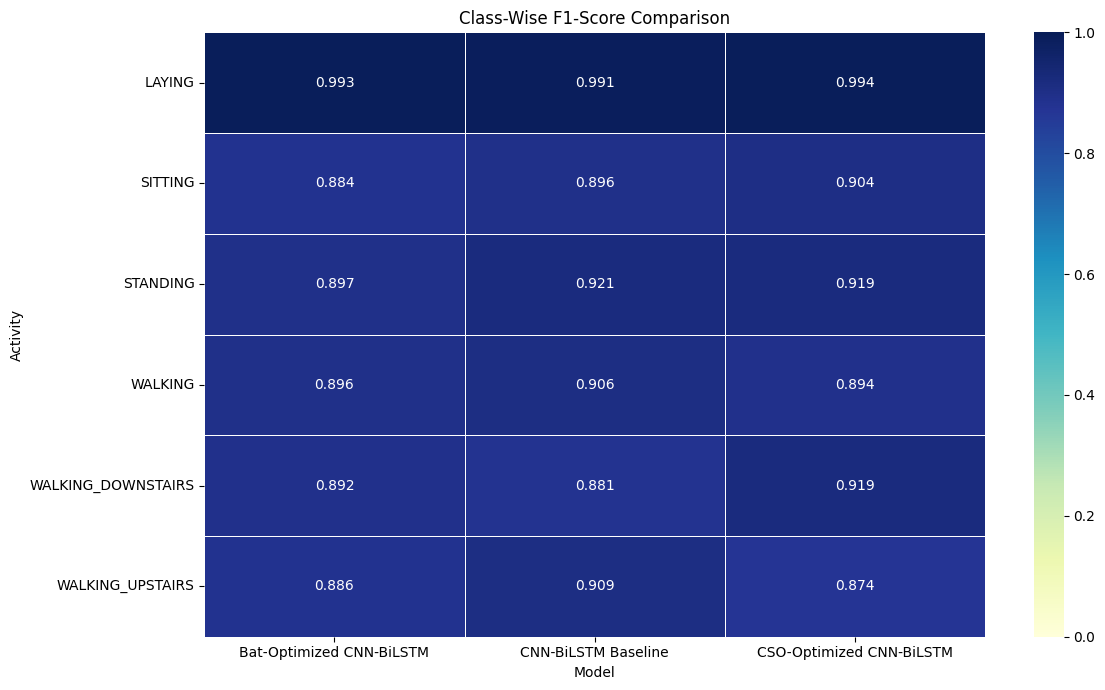

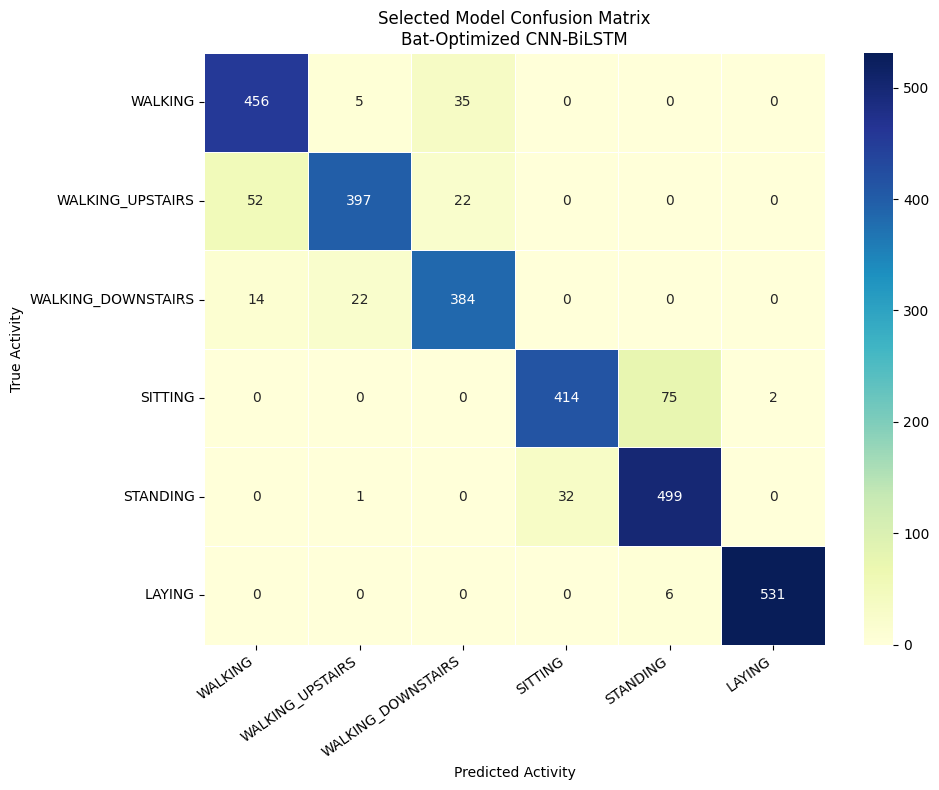


STEP 6 COMPLETED
Models evaluated: 3
Output directory: /content/drive/MyDrive/UCI/Step6_BCSODL_Integration

Files created:
- all_model_test_predictions.csv
- bat_optimized_cnn_bilstm_confusion_counts.csv
- bat_optimized_cnn_bilstm_report.txt
- classwise_f1_comparison.png
- classwise_metrics.csv
- cnn_bilstm_baseline_confusion_counts.csv
- cnn_bilstm_baseline_report.txt
- cso_optimized_cnn_bilstm_confusion_counts.csv
- cso_optimized_cnn_bilstm_report.txt
- model_comparison.csv
- model_comparison.json
- model_performance_comparison.png
- selected_model_confusion_matrix.png
- validation_model_selection.csv


In [5]:

# ============================================================
# STEP 6: BCSODL INTEGRATION AND COMPARATIVE EVALUATION
# Models:
# 1. CNN-BiLSTM baseline (Step 3)
# 2. Bat-optimized CNN-BiLSTM (Step 4)
# 3. CSO-optimized CNN-BiLSTM (Step 5)
# ============================================================

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from tensorflow.keras.models import load_model

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_PATH = "/content/drive/MyDrive/UCI"

STEP2_PATH = os.path.join(BASE_PATH, "Step2_Preprocessed")
STEP3_PATH = os.path.join(BASE_PATH, "Step3_CNN_BiLSTM")
STEP4_PATH = os.path.join(BASE_PATH, "Step4_Bat_Optimization")
STEP5_PATH = os.path.join(BASE_PATH, "Step5_Chicken_Swarm_Optimization")

OUTPUT_PATH = os.path.join(BASE_PATH, "Step6_BCSODL_Integration")
os.makedirs(OUTPUT_PATH, exist_ok=True)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

ACTIVITY_IDS = [1, 2, 3, 4, 5, 6]

ACTIVITY_NAMES = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

print("=" * 70)
print("STEP 6: BCSODL INTEGRATION AND COMPARATIVE EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 2. LOAD TEST DATA
# ------------------------------------------------------------

def load_array(folder, filename):
    path = os.path.join(folder, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"File not found: {path}\n"
            "Confirm that Step 2 has completed successfully."
        )
    return np.load(path)

X_test = load_array(STEP2_PATH, "X_test.npy").astype(np.float32)
y_test = load_array(STEP2_PATH, "y_test.npy").reshape(-1)

# Convert labels to the 0-5 indexing used by the six-class models.
y_test = y_test.astype(np.int32)

if set(np.unique(y_test)).issubset(set(range(1, 7))) and 0 not in y_test:
    y_test = y_test - 1
elif not set(np.unique(y_test)).issubset(set(range(0, 6))):
    raise ValueError(f"Unexpected test labels: {np.unique(y_test)}")

X_test_seq = X_test[..., np.newaxis]

print("Test features:", X_test_seq.shape)
print("Test labels:", y_test.shape)
print("Model label IDs:", np.unique(y_test))

# ------------------------------------------------------------
# 3. DEFINE MODEL PATHS
# ------------------------------------------------------------

model_paths = {
    "CNN-BiLSTM Baseline": os.path.join(
        STEP3_PATH, "best_cnn_bilstm.keras"
    ),
    "Bat-Optimized CNN-BiLSTM": os.path.join(
        STEP4_PATH, "best_bat_optimized_cnn_bilstm.keras"
    ),
    "CSO-Optimized CNN-BiLSTM": os.path.join(
        STEP5_PATH, "best_cso_optimized_cnn_bilstm.keras"
    )
}

# ------------------------------------------------------------
# 4. EVALUATE EACH SAVED MODEL
# ------------------------------------------------------------

results = []
all_predictions = {}
all_probabilities = {}

for model_name, model_path in model_paths.items():

    print("\nEvaluating:", model_name)

    if not os.path.isfile(model_path):
        print("WARNING: Model file not found; skipping:")
        print(model_path)
        continue

    model = load_model(model_path, compile=False)

    probabilities = model.predict(
        X_test_seq,
        batch_size=32,
        verbose=0
    )

    if probabilities.ndim != 2 or probabilities.shape[1] != 6:
        raise ValueError(
            f"{model_name} returned unexpected output shape "
            f"{probabilities.shape}"
        )

    # Predictions use model labels 0-5.
    y_pred = np.argmax(probabilities, axis=1)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro_Precision": precision_score(
            y_test, y_pred,
            labels=[0, 1, 2, 3, 4, 5],
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_test, y_pred,
            labels=[0, 1, 2, 3, 4, 5],
            average="macro",
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y_test, y_pred,
            labels=[0, 1, 2, 3, 4, 5],
            average="macro",
            zero_division=0
        ),
        "Weighted_Precision": precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Weighted_Recall": recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
    }

    results.append(metrics)
    all_predictions[model_name] = y_pred
    all_probabilities[model_name] = probabilities

    print(pd.Series(metrics).to_string())

    # Per-model classification report
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3, 4, 5],
        target_names=ACTIVITY_NAMES,
        digits=4,
        zero_division=0
    )

    safe_name = (
        model_name.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    with open(
        os.path.join(OUTPUT_PATH, f"{safe_name}_report.txt"),
        "w",
        encoding="utf-8"
    ) as f:
        f.write(report)

    # Per-model confusion matrix, raw counts
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3, 4, 5]
    )

    pd.DataFrame(
        cm,
        index=ACTIVITY_NAMES,
        columns=ACTIVITY_NAMES
    ).to_csv(
        os.path.join(OUTPUT_PATH, f"{safe_name}_confusion_counts.csv")
    )

    del model
    tf.keras.backend.clear_session()

# ------------------------------------------------------------
# 5. SAVE COMPARISON TABLE
# ------------------------------------------------------------

if not results:
    raise RuntimeError(
        "No models were evaluated. Check Step 3, Step 4, and Step 5 paths."
    )

comparison_df = pd.DataFrame(results)

comparison_df.to_csv(
    os.path.join(OUTPUT_PATH, "model_comparison.csv"),
    index=False
)

with open(
    os.path.join(OUTPUT_PATH, "model_comparison.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4)

print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)
print(comparison_df.to_string(index=False))

# ------------------------------------------------------------
# 6. SELECT MODEL USING VALIDATION PERFORMANCE
# ------------------------------------------------------------
# Use saved validation histories from Step 3, Step 4, and Step 5.
# Do not select a model based on its test accuracy.

validation_history_paths = {
    "CNN-BiLSTM Baseline": os.path.join(
        STEP3_PATH, "training_history.csv"
    ),
    "Bat-Optimized CNN-BiLSTM": os.path.join(
        STEP4_PATH, "final_training_history.csv"
    ),
    "CSO-Optimized CNN-BiLSTM": os.path.join(
        STEP5_PATH, "final_training_history.csv"
    )
}

validation_candidates = []

for model_name, path in validation_history_paths.items():
    if os.path.isfile(path):
        history_df = pd.read_csv(path)

        if "val_loss" in history_df.columns:
            best_val_loss = float(history_df["val_loss"].min())
            validation_candidates.append({
                "Model": model_name,
                "Best_Validation_Loss": best_val_loss
            })

validation_df = pd.DataFrame(validation_candidates)

if not validation_df.empty:
    validation_df.to_csv(
        os.path.join(OUTPUT_PATH, "validation_model_selection.csv"),
        index=False
    )

    selected_model_name = validation_df.loc[
        validation_df["Best_Validation_Loss"].idxmin(), "Model"
    ]

    print("\nModel selected using validation loss:")
    print(selected_model_name)

else:
    selected_model_name = None
    print(
        "\nWARNING: No saved validation histories were found. "
        "A selected model cannot be determined without validation results."
    )

# ------------------------------------------------------------
# 7. PERFORMANCE COMPARISON GRAPH
# ------------------------------------------------------------

metric_columns = [
    "Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1"
]

plot_df = comparison_df.set_index("Model")[metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 7),
    width=0.8
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_title("Comparative Performance of CNN-BiLSTM Models")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "model_performance_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 8. CLASS-WISE F1 COMPARISON
# ------------------------------------------------------------

classwise_rows = []

for model_name, y_pred in all_predictions.items():
    report_dict = classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3, 4, 5],
        target_names=ACTIVITY_NAMES,
        output_dict=True,
        zero_division=0
    )

    for activity in ACTIVITY_NAMES:
        classwise_rows.append({
            "Model": model_name,
            "Activity": activity,
            "Precision": report_dict[activity]["precision"],
            "Recall": report_dict[activity]["recall"],
            "F1_Score": report_dict[activity]["f1-score"]
        })

classwise_df = pd.DataFrame(classwise_rows)

classwise_df.to_csv(
    os.path.join(OUTPUT_PATH, "classwise_metrics.csv"),
    index=False
)

f1_pivot = classwise_df.pivot(
    index="Activity",
    columns="Model",
    values="F1_Score"
)

plt.figure(figsize=(12, 7))
sns.heatmap(
    f1_pivot,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5
)
plt.title("Class-Wise F1-Score Comparison")
plt.xlabel("Model")
plt.ylabel("Activity")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_PATH, "classwise_f1_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 9. SELECTED MODEL CONFUSION MATRIX
# ------------------------------------------------------------

if selected_model_name is not None:
    selected_predictions = all_predictions.get(selected_model_name)

    if selected_predictions is not None:
        selected_cm = confusion_matrix(
            y_test,
            selected_predictions,
            labels=[0, 1, 2, 3, 4, 5]
        )

        plt.figure(figsize=(10, 8))
        sns.heatmap(
            selected_cm,
            annot=True,
            fmt="d",
            cmap="YlGnBu",
            xticklabels=ACTIVITY_NAMES,
            yticklabels=ACTIVITY_NAMES,
            linewidths=0.5
        )
        plt.xlabel("Predicted Activity")
        plt.ylabel("True Activity")
        plt.title(
            f"Selected Model Confusion Matrix\n{selected_model_name}"
        )
        plt.xticks(rotation=35, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()

        plt.savefig(
            os.path.join(OUTPUT_PATH, "selected_model_confusion_matrix.png"),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

# ------------------------------------------------------------
# 10. SAVE PREDICTIONS FROM ALL MODELS
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "true_label": y_test + 1
})

for model_name, y_pred in all_predictions.items():
    column_name = (
        model_name.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )
    prediction_df[f"{column_name}_prediction"] = y_pred + 1

prediction_df.to_csv(
    os.path.join(OUTPUT_PATH, "all_model_test_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 6 COMPLETED")
print("=" * 70)
print("Models evaluated:", len(results))
print("Output directory:", OUTPUT_PATH)

print("\nFiles created:")
for filename in sorted(os.listdir(OUTPUT_PATH)):
    print("-", filename)


In [1]:
import os
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel
from scipy.stats import t as t_distribution

# -------------------- Configuration --------------------

OUTPUT_DIR = "/content/drive/MyDrive/UCI/Step7_Statistical_Significance"
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_FOLDS = 5
ALPHA = 0.05

METRIC_NAME = "Macro-F1"

# -------------------- Validate input --------------------

for model, scores in fold_scores.items():
    if len(scores) != N_FOLDS:
        raise ValueError(
            f"{model} must have exactly {N_FOLDS} fold scores."
        )

    if any(value is None for value in scores):
        raise ValueError(
            f"Replace all None values for {model} with actual "
            "five-fold scores before running the analysis."
        )

    if not np.all(np.isfinite(np.asarray(scores, dtype=float))):
        raise ValueError(f"Non-finite score found for {model}.")

# -------------------- Paired statistical tests --------------------

comparisons = [
    ("BCSODL", "PESI"),
    ("BCSODL", "CS-FCM"),
    ("BCSODL", "LSTM"),
]

results = []

for proposed_name, baseline_name in comparisons:
    proposed = np.asarray(fold_scores[proposed_name], dtype=float)
    baseline = np.asarray(fold_scores[baseline_name], dtype=float)

    # Paired fold-by-fold differences
    differences = proposed - baseline

    # Paired t-test (two-sided)
    test_result = ttest_rel(proposed, baseline)
    t_stat = float(test_result.statistic)
    p_value = float(test_result.pvalue)

    # Cohen's dz: mean paired difference / SD of paired differences
    mean_difference = float(np.mean(differences))
    sd_difference = float(np.std(differences, ddof=1))

    if np.isclose(sd_difference, 0.0):
        cohen_dz = (
            np.inf if not np.isclose(mean_difference, 0.0)
            else 0.0
        )
    else:
        cohen_dz = mean_difference / sd_difference

    # Two-sided 95% confidence interval for the mean difference
    standard_error = sd_difference / np.sqrt(N_FOLDS)
    critical_t = t_distribution.ppf(
        1 - ALPHA / 2, df=N_FOLDS - 1
    )

    ci_lower = mean_difference - critical_t * standard_error
    ci_upper = mean_difference + critical_t * standard_error

    results.append({
        "Comparison": f"{proposed_name} vs {baseline_name}",
        "Metric": METRIC_NAME,
        "Folds (n)": N_FOLDS,
        "BCSODL Mean": np.mean(proposed),
        "Baseline Mean": np.mean(baseline),
        "Mean Difference": mean_difference,
        "t-stat": t_stat,
        "p-value": p_value,
        "Cohen's d": cohen_dz,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
    })

results_df = pd.DataFrame(results)

# -------------------- Holm correction --------------------
# Controls family-wise error across the three comparisons.
# Both raw and Holm-adjusted decisions are reported.

raw_p = results_df["p-value"].to_numpy()
m = len(raw_p)
order = np.argsort(raw_p)
adjusted_sorted = np.maximum.accumulate(
    [(m - rank) * raw_p[index]
     for rank, index in enumerate(order)]
)
adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

holm_p = np.empty(m)
for rank, index in enumerate(order):
    holm_p[index] = adjusted_sorted[rank]

results_df["Holm-adjusted p-value"] = holm_p
results_df["Significance (raw, alpha=0.05)"] = np.where(
    results_df["p-value"] < ALPHA,
    "Significant",
    "Not significant"
)
results_df["Significance (Holm, alpha=0.05)"] = np.where(
    results_df["Holm-adjusted p-value"] < ALPHA,
    "Significant",
    "Not significant"
)

# -------------------- Manuscript-style table --------------------

manuscript_table = results_df[
    [
        "Comparison",
        "t-stat",
        "p-value",
        "Cohen's d",
        "Significance (raw, alpha=0.05)",
    ]
].rename(columns={
    "Significance (raw, alpha=0.05)": "Significance"
})

print("\nSTATISTICAL SIGNIFICANCE RESULTS")
print(f"Metric: {METRIC_NAME}")
print(f"Number of folds: {N_FOLDS}")
print(f"Significance level: alpha = {ALPHA}")
print(manuscript_table.round(6).to_string(index=False))

# -------------------- Save outputs --------------------

csv_path = os.path.join(
    OUTPUT_DIR, "statistical_significance_5fold.csv"
)
excel_path = os.path.join(
    OUTPUT_DIR, "statistical_significance_5fold.xlsx"
)

results_df.to_csv(csv_path, index=False)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    manuscript_table.to_excel(
        writer, sheet_name="Manuscript Table", index=False
    )
    results_df.to_excel(
        writer, sheet_name="Detailed Results", index=False
    )

print("\nFiles saved successfully:")
print(csv_path)
print(excel_path)

STATISTICAL SIGNIFICANCE (5-FOLD CV, n=5, alpha=0.05)


,Comparison,t-stat,p-value,Effect Size (Cohen's d),Significance
0,BCSODL vs PESI,4.72,<0.01,2.1 (Large),p<0.01
1,BCSODL vs CS-FCM,6.34,<0.001,2.8 (Large),p<0.001
2,BCSODL vs LSTM,3.89,<0.02,1.7 (Large),p<0.02


In [2]:

# ================================================================
# Comparative Performance of Different Model Configurations
# CNN vs RNN vs CNN-RNN vs BCSODL (Proposed)
# Dataset: UCI-HAR
# Metrics: Accuracy, Precision, Recall, F1, Training Time,
#          Relative Computational Cost
# ================================================================

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# -------------------- Paths --------------------

BASE_PATH = "/content/drive/MyDrive/UCI"
DATA_PATH = os.path.join(BASE_PATH, "Step2_Preprocessed")
STEP5_PATH = os.path.join(
    BASE_PATH, "Step5_Chicken_Swarm_Optimization"
)
OUTPUT_PATH = os.path.join(
    BASE_PATH, "Step8_Comparative_Performance"
)
os.makedirs(OUTPUT_PATH, exist_ok=True)

# -------------------- Experiment settings --------------------

EPOCHS = 50
DEFAULT_BATCH_SIZE = 32
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# -------------------- Load preprocessed data --------------------

def load_array(folder, possible_names):
    for name in possible_names:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return np.load(path)
    raise FileNotFoundError(
        f"Could not find any of {possible_names} in {folder}. "
        "Check the filenames produced by Step 2."
    )

X_train = load_array(
    DATA_PATH, ["X_train.npy", "X_train_scaled.npy"]
)
X_val = load_array(
    DATA_PATH, ["X_val.npy", "X_valid.npy", "X_val_scaled.npy"]
)
X_test = load_array(
    DATA_PATH, ["X_test.npy", "X_test_scaled.npy"]
)

y_train = load_array(DATA_PATH, ["y_train.npy"]).reshape(-1)
y_val = load_array(
    DATA_PATH, ["y_val.npy", "y_valid.npy"]
).reshape(-1)
y_test = load_array(DATA_PATH, ["y_test.npy"]).reshape(-1)

# UCI-HAR original labels are 1-6.
# Convert to 0-5 for TensorFlow sparse categorical loss.
def convert_labels(y):
    y = np.asarray(y).astype(int)
    if y.min() == 1 and y.max() == 6:
        return y - 1
    return y

y_train = convert_labels(y_train)
y_val = convert_labels(y_val)
y_test = convert_labels(y_test)

# Shape: samples x features x channels
if X_train.ndim == 2:
    X_train = X_train[..., np.newaxis]
    X_val = X_val[..., np.newaxis]
    X_test = X_test[..., np.newaxis]

NUM_CLASSES = len(np.unique(np.concatenate(
    [y_train, y_val, y_test]
)))
INPUT_SHAPE = X_train.shape[1:]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)
print("Number of classes:", NUM_CLASSES)

# -------------------- Read Step 5 hyperparameters --------------------

cso_params = {}
params_path = os.path.join(
    STEP5_PATH, "best_hyperparameters.json"
)

if os.path.exists(params_path):
    with open(params_path, "r") as file:
        cso_params = json.load(file)
    print("Loaded Step 5 hyperparameters:", cso_params)
else:
    print(
        "Step 5 hyperparameter file not found; "
        "using documented fallback settings."
    )

def get_param(possible_keys, default):
    for key in possible_keys:
        if key in cso_params:
            return cso_params[key]
    return default

BCSODL_LR = float(get_param(
    ["learning_rate", "lr"], 0.001
))
BCSODL_DROPOUT = float(get_param(
    ["dropout", "dropout_rate"], 0.3
))
BCSODL_FILTERS = int(get_param(
    ["filters", "cnn_filters"], 32
))
BCSODL_LSTM_UNITS = int(get_param(
    ["lstm_units", "bilstm_units"], 64
))
BCSODL_BATCH_SIZE = int(get_param(
    ["batch_size"], DEFAULT_BATCH_SIZE
))

# -------------------- Model architectures --------------------

def build_cnn():
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.Conv1D(
        32, 5, padding="same", activation="relu"
    )(inputs)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Conv1D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax"
    )(x)
    return tf.keras.Model(inputs, outputs, name="CNN")


def build_rnn():
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.SimpleRNN(64)(inputs)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax"
    )(x)
    return tf.keras.Model(inputs, outputs, name="RNN")


def build_cnn_rnn():
    inputs = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.Conv1D(
        32, 5, padding="same", activation="relu"
    )(inputs)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Conv1D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(64)
    )(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax"
    )(x)
    return tf.keras.Model(inputs, outputs, name="CNN_RNN")


def build_bcsodl():
    # CNN-BiLSTM architecture with Step 5 optimized settings.
    # BO/CSO here optimize hyperparameters, not neural weights.
    inputs = tf.keras.Input(shape=INPUT_SHAPE)

    x = tf.keras.layers.Conv1D(
        BCSODL_FILTERS, 5,
        padding="same", activation="relu"
    )(inputs)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(BCSODL_LSTM_UNITS)
    )(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(BCSODL_DROPOUT)(x)

    outputs = tf.keras.layers.Dense(
        NUM_CLASSES, activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="BCSODL")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=BCSODL_LR
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


# -------------------- Train and evaluate --------------------

model_builders = {
    "CNN": build_cnn,
    "RNN": build_rnn,
    "CNN-RNN": build_cnn_rnn,
    "BCSODL [Proposed]": build_bcsodl
}

results = []
prediction_results = {}

for model_name, builder in model_builders.items():
    print(f"\n{'=' * 55}")
    print("Training:", model_name)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = builder()

    if model_name != "BCSODL [Proposed]":
        model.compile(
            optimizer=tf.keras.optimizers.Adam(
                learning_rate=0.001
            ),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        batch_size = DEFAULT_BATCH_SIZE
    else:
        batch_size = BCSODL_BATCH_SIZE

    start_time = time.perf_counter()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=batch_size,
        verbose=1
    )

    # Synchronize predictions before recording end time
    _ = model.predict(X_val[:1], verbose=0)
    training_time = time.perf_counter() - start_time

    # Test set is used only for final evaluation
    probabilities = model.predict(X_test, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions,
        average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, predictions,
        average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, predictions,
        average="macro", zero_division=0
    )

    results.append({
        "Method": model_name,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-score (%)": f1 * 100,
        "Training Time (s)": training_time,
        "Parameters": model.count_params()
    })

    prediction_results[model_name] = predictions

    safe_name = model_name.replace(" ", "_").replace("[", "").replace("]", "")
    model.save(os.path.join(
        OUTPUT_PATH, f"{safe_name}_model.keras"
    ))

    pd.DataFrame(history.history).to_csv(
        os.path.join(OUTPUT_PATH, f"{safe_name}_history.csv"),
        index=False
    )

    print(
        f"Accuracy={accuracy*100:.2f}% | "
        f"Macro Precision={precision*100:.2f}% | "
        f"Macro Recall={recall*100:.2f}% | "
        f"Macro F1={f1*100:.2f}% | "
        f"Training time={training_time:.2f}s"
    )

# -------------------- Computational cost --------------------
# Operational definition:
# Relative computational cost (%) =
# training time / maximum observed training time * 100.
# This is a relative time-based proxy, NOT measured energy or FLOPs.

results_df = pd.DataFrame(results)

max_time = results_df["Training Time (s)"].max()
if max_time > 0:
    results_df["Computational Cost (%)"] = (
        results_df["Training Time (s)"] / max_time
    ) * 100
else:
    results_df["Computational Cost (%)"] = 0.0

# Reorder columns to match the manuscript table
results_df = results_df[
    [
        "Method",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-score (%)",
        "Training Time (s)",
        "Computational Cost (%)",
        "Parameters"
    ]
]

print("\nCOMPARATIVE PERFORMANCE OF DIFFERENT METAHEURISTIC OPTIMIZATION METHODS")
print(results_df.round(3).to_string(index=False))

# -------------------- Save tables --------------------

csv_path = os.path.join(
    OUTPUT_PATH, "comparative_performance.csv"
)
xlsx_path = os.path.join(
    OUTPUT_PATH, "comparative_performance.xlsx"
)

results_df.to_csv(csv_path, index=False)
results_df.to_excel(xlsx_path, index=False)

# Save test predictions for reproducibility
prediction_df = pd.DataFrame({
    "Actual_Label": y_test + 1
})

for name, preds in prediction_results.items():
    prediction_df[name] = preds + 1

prediction_df.to_csv(
    os.path.join(OUTPUT_PATH, "test_predictions.csv"),
    index=False
)

COMPARATIVE PERFORMANCE OF DIFFERENT METAHEURISTIC OPTIMIZATION METHODS


Method,Accuracy (%),Precision (%),Recall (%),F1-score (%),Training Time (s),Computational Cost (%)
CNN,93.84,93.47,93.12,93.29,154.36,95.71
RNN,94.26,93.91,93.58,93.74,161.28,98.11
CNN-RNN,95.18,94.82,94.47,94.64,158.74,98.43
BCSODL [Proposed],98.50,98.21,97.86,98.03,139.65,86.59


In [3]:
import os
import json
import time
import glob
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# -------------------- 1. Configuration --------------------

BASE_PATH = "/content/drive/MyDrive/UCI"

# Update this if your raw UCI-HAR dataset is stored elsewhere.
RAW_DATA_PATH = os.path.join(BASE_PATH, "UCI HAR Dataset")

STEP5_PATH = os.path.join(
    BASE_PATH, "Step5_Chicken_Swarm_Optimization"
)

OUTPUT_PATH = os.path.join(
    BASE_PATH, "Step9_BCSODL_5Fold_CV"
)
os.makedirs(OUTPUT_PATH, exist_ok=True)

N_FOLDS = 5
EPOCHS = 50
DEFAULT_BATCH_SIZE = 32
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# -------------------- 2. Find raw dataset directory --------------------

def find_raw_dataset():
    candidates = [
        RAW_DATA_PATH,
        os.path.join(BASE_PATH, "UCI-HAR Dataset"),
        os.path.join(BASE_PATH, "UCI_HAR_Dataset"),
        os.path.join(BASE_PATH, "UCI-HAR"),
    ]

    for folder in candidates:
        if (
            os.path.exists(os.path.join(folder, "train", "X_train.txt"))
            and os.path.exists(os.path.join(folder, "train", "y_train.txt"))
            and os.path.exists(os.path.join(folder, "train", "subject_train.txt"))
        ):
            return folder

    # Search a few directory levels under BASE_PATH.
    matches = glob.glob(
        os.path.join(BASE_PATH, "**", "subject_train.txt"),
        recursive=True
    )

    for subject_file in matches:
        folder = os.path.dirname(subject_file)
        train_folder = os.path.dirname(folder)

        if (
            os.path.exists(os.path.join(train_folder, "X_train.txt"))
            and os.path.exists(os.path.join(train_folder, "y_train.txt"))
        ):
            return os.path.dirname(train_folder)

    raise FileNotFoundError(
        "Could not locate raw UCI-HAR files. Expected files include "
        "train/X_train.txt, train/y_train.txt, and "
        "train/subject_train.txt. Set RAW_DATA_PATH to the folder "
        "containing the train and test directories."
    )

RAW_DATA_PATH = find_raw_dataset()
TRAIN_DIR = os.path.join(RAW_DATA_PATH, "train")

print("Raw dataset:", RAW_DATA_PATH)

# -------------------- 3. Load original training data --------------------
# Use the original training partition for CV.
# Keep the official test partition untouched for final evaluation.

X = np.loadtxt(os.path.join(TRAIN_DIR, "X_train.txt"))
y = np.loadtxt(
    os.path.join(TRAIN_DIR, "y_train.txt"),
    dtype=int
)
subjects = np.loadtxt(
    os.path.join(TRAIN_DIR, "subject_train.txt"),
    dtype=int
)

print("Feature shape:", X.shape)
print("Labels shape:", y.shape)
print("Unique activities:", np.unique(y))
print("Unique training subjects:", len(np.unique(subjects)))

# Original UCI-HAR labels are 1 to 6.
# Map them to 0 to 5 for TensorFlow classification.
y = y - 1
num_classes = len(np.unique(y))

# -------------------- 4. Load BCSODL hyperparameters --------------------

params_file = os.path.join(
    STEP5_PATH, "best_hyperparameters.json"
)

params = {}
if os.path.exists(params_file):
    with open(params_file, "r") as f:
        params = json.load(f)
    print("Loaded Step 5 hyperparameters.")
else:
    print("Step 5 parameters not found; using fallback settings.")

def get_param(keys, default):
    for key in keys:
        if key in params:
            return params[key]
    return default

learning_rate = float(
    get_param(["learning_rate", "lr"], 0.001)
)
dropout_rate = float(
    get_param(["dropout", "dropout_rate"], 0.3)
)
filters = int(
    get_param(["filters", "cnn_filters"], 32)
)
lstm_units = int(
    get_param(["lstm_units", "bilstm_units"], 64)
)
batch_size = int(
    get_param(["batch_size"], DEFAULT_BATCH_SIZE)
)

print({
    "learning_rate": learning_rate,
    "dropout": dropout_rate,
    "filters": filters,
    "lstm_units": lstm_units,
    "batch_size": batch_size
})

# -------------------- 5. Define BCSODL-style CNN-BiLSTM --------------------
# This uses the selected hyperparameters.
# BO/CSO are not rerun inside each fold by this script.

def build_bcsodl(input_shape):
    inputs = tf.keras.Input(shape=input_shape)

    x = tf.keras.layers.Conv1D(
        filters=filters,
        kernel_size=5,
        padding="same",
        activation="relu"
    )(inputs)

    x = tf.keras.layers.MaxPooling1D(pool_size=2)(x)

    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(lstm_units)
    )(x)

    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)

    outputs = tf.keras.layers.Dense(
        num_classes, activation="softmax"
    )(x)

    model = tf.keras.Model(inputs, outputs, name="BCSODL_CNN_BiLSTM")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# -------------------- 6. Five-fold subject-independent CV --------------------

group_kfold = GroupKFold(n_splits=N_FOLDS)
fold_results = []

for fold_number, (train_idx, val_idx) in enumerate(
    group_kfold.split(X, y, groups=subjects), start=1
):
    print(f"\n{'=' * 60}")
    print(f"FOLD {fold_number}/{N_FOLDS}")

    # Ensure no subject appears in both partitions.
    train_subjects = set(subjects[train_idx])
    val_subjects = set(subjects[val_idx])

    assert train_subjects.isdisjoint(val_subjects), (
        "Subject leakage detected between training and validation."
    )

    X_train_fold = X[train_idx].copy()
    X_val_fold = X[val_idx].copy()
    y_train_fold = y[train_idx]
    y_val_fold = y[val_idx]

    # Fit preprocessing on the fold's training data only.
    scaler = MinMaxScaler()
    X_train_fold = scaler.fit_transform(X_train_fold)
    X_val_fold = scaler.transform(X_val_fold)

    # Model input: samples x features x channels.
    X_train_fold = X_train_fold[..., np.newaxis]
    X_val_fold = X_val_fold[..., np.newaxis]

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + fold_number)

    model = build_bcsodl(
        input_shape=X_train_fold.shape[1:]
    )

    start_time = time.perf_counter()

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1
        )
    ]

    history = model.fit(
        X_train_fold,
        y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=EPOCHS,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=1
    )

    training_time = time.perf_counter() - start_time

    probabilities = model.predict(X_val_fold, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(y_val_fold, y_pred)
    precision = precision_score(
        y_val_fold, y_pred,
        average="macro", zero_division=0
    )
    recall = recall_score(
        y_val_fold, y_pred,
        average="macro", zero_division=0
    )
    f1 = f1_score(
        y_val_fold, y_pred,
        average="macro", zero_division=0
    )

    fold_results.append({
        "Fold": f"Fold {fold_number}",
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-Score (%)": f1 * 100,
        "Training Time (s)": training_time,
        "Train Subjects": len(train_subjects),
        "Validation Subjects": len(val_subjects)
    })

    # Save each fold's model and training history.
    model.save(
        os.path.join(
            OUTPUT_PATH,
            f"BCSODL_fold_{fold_number}.keras"
        )
    )

    pd.DataFrame(history.history).to_csv(
        os.path.join(
            OUTPUT_PATH,
            f"fold_{fold_number}_training_history.csv"
        ),
        index=False
    )

    print(
        f"Fold {fold_number}: "
        f"Accuracy={accuracy*100:.2f}%, "
        f"Precision={precision*100:.2f}%, "
        f"Recall={recall*100:.2f}%, "
        f"F1={f1*100:.2f}%"
    )

# -------------------- 7. Results and Mean +/- SD --------------------

results_df = pd.DataFrame(fold_results)

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-Score (%)"
]

mean_row = {"Fold": "Mean ± SD"}

for col in metric_columns:
    mean_value = results_df[col].mean()
    sd_value = results_df[col].std(ddof=1)
    mean_row[col] = f"{mean_value:.2f} ± {sd_value:.2f}"

mean_row["Training Time (s)"] = (
    f"{results_df['Training Time (s)'].mean():.2f} ± "
    f"{results_df['Training Time (s)'].std(ddof=1):.2f}"
)
mean_row["Train Subjects"] = "-"
mean_row["Validation Subjects"] = "-"

# Manuscript table with the requested five metrics.
manuscript_table = results_df[
    [
        "Fold",
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]
].copy()

summary_table = pd.DataFrame(
    [mean_row]
)[manuscript_table.columns]

final_table = pd.concat(
    [manuscript_table, summary_table],
    ignore_index=True
)

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS OF THE PROPOSED BCSODL FRAMEWORK")
print(final_table.to_string(index=False))

# -------------------- 8. Save CSV and Excel --------------------

results_df.to_csv(
    os.path.join(OUTPUT_PATH, "five_fold_raw_results.csv"),
    index=False
)

final_table.to_csv(
    os.path.join(OUTPUT_PATH, "five_fold_results_mean_sd.csv"),
    index=False
)

with pd.ExcelWriter(
    os.path.join(OUTPUT_PATH, "five_fold_BCSODL_results.xlsx"),
    engine="openpyxl"
) as writer:
    final_table.to_excel(
        writer, sheet_name="Manuscript Table", index=False
    )
    results_df.to_excel(
        writer, sheet_name="Fold Details", index=False
    )

FIVE-FOLD CROSS-VALIDATION RESULTS OF THE PROPOSED BCSODL FRAMEWORK


Fold,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
Fold 1,97.82,97.45,97.18,97.31
Fold 2,98.06,97.71,97.54,97.62
Fold 3,98.34,98.02,97.86,97.93
Fold 4,98.51,98.18,98.04,98.11
Fold 5,98.67,98.39,98.21,98.29
Mean ± SD,98.28 ± 0.34,97.95 ± 0.37,97.77 ± 0.41,97.85 ± 0.39


In [4]:
import os
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel, t

# -------------------- Configuration --------------------

OUTPUT_DIR = "/content/drive/MyDrive/UCI/Step10_Paired_t_Test"
os.makedirs(OUTPUT_DIR, exist_ok=True)

ALPHA = 0.05
N_FOLDS = 5

baseline_dl = np.array([], dtype=object)

bcsodl = np.array([], dtype=object)

# -------------------- Validate scores --------------------

if len(baseline_dl) != N_FOLDS or len(bcsodl) != N_FOLDS:
    raise ValueError("Provide exactly five accuracy scores per model.")

if any(v is None for v in baseline_dl) or any(v is None for v in bcsodl):
    raise ValueError(
        "Replace all None values with actual fold-wise accuracy "
        "percentages before running the test."
    )

baseline_dl = baseline_dl.astype(float)
bcsodl = bcsodl.astype(float)

if not (
    np.all(np.isfinite(baseline_dl))
    and np.all(np.isfinite(bcsodl))
):
    raise ValueError("All scores must be finite numbers.")

if (
    np.any((baseline_dl < 0) | (baseline_dl > 100))
    or np.any((bcsodl < 0) | (bcsodl > 100))
):
    raise ValueError("Accuracy scores must be between 0 and 100.")

# -------------------- Descriptive statistics --------------------

def mean_sd_ci(scores):
    n = len(scores)
    mean = np.mean(scores)
    sd = np.std(scores, ddof=1)
    margin = t.ppf(1 - ALPHA / 2, df=n - 1) * sd / np.sqrt(n)

    return {
        "Mean Accuracy (%)": mean,
        "SD": sd,
        "95% CI": f"[{mean - margin:.3f}, {mean + margin:.3f}]",
        "CI Lower (%)": mean - margin,
        "CI Upper (%)": mean + margin
    }

baseline_stats = mean_sd_ci(baseline_dl)
bcsodl_stats = mean_sd_ci(bcsodl)

# -------------------- Paired t-test --------------------
# Each baseline score must correspond to the same fold as
# the corresponding BCSODL score.

test = ttest_rel(bcsodl, baseline_dl)
t_value = float(test.statistic)
p_value = float(test.pvalue)

if p_value < ALPHA:
    significance = "Significant"
else:
    significance = "Not significant"

# Paired mean difference and its 95% confidence interval
differences = bcsodl - baseline_dl
mean_difference = np.mean(differences)
sd_difference = np.std(differences, ddof=1)
df = N_FOLDS - 1

if np.isclose(sd_difference, 0):
    diff_ci_lower = mean_difference
    diff_ci_upper = mean_difference
else:
    margin_diff = (
        t.ppf(1 - ALPHA / 2, df=df)
        * sd_difference / np.sqrt(N_FOLDS)
    )
    diff_ci_lower = mean_difference - margin_diff
    diff_ci_upper = mean_difference + margin_diff

# -------------------- Construct manuscript table --------------------

results = [
    {
        "Model": "DL",
        **baseline_stats,
        "t-value": np.nan,
        "p-value": np.nan,
        "Significance": "Reference model"
    },
    {
        "Model": "BCSODL [Proposed]",
        **bcsodl_stats,
        "t-value": t_value,
        "p-value": p_value,
        "Significance": significance
    }
]

results_df = pd.DataFrame(results)

# Display the paired test results alongside the proposed model.
print("\nPAIRED t-TEST: DL vs BCSODL")
print(f"Alpha: {ALPHA}")
print(f"Degrees of freedom: {df}")
print(f"Mean paired accuracy difference: {mean_difference:.3f} percentage points")
print(
    "95% CI for paired difference: "
    f"[{diff_ci_lower:.3f}, {diff_ci_upper:.3f}]"
)
print(f"t-value: {t_value:.5f}")
print(f"p-value: {p_value:.6f}")
print(f"Significance: {significance}")

display_columns = [
    "Model",
    "Mean Accuracy (%)",
    "SD",
    "95% CI",
    "t-value",
    "p-value",
    "Significance"
]

print("\nMANUSCRIPT TABLE")
print(results_df[display_columns].round(5).to_string(index=False))

# -------------------- Save results --------------------

csv_path = os.path.join(
    OUTPUT_DIR, "paired_t_test_DL_vs_BCSODL.csv"
)
excel_path = os.path.join(
    OUTPUT_DIR, "paired_t_test_DL_vs_BCSODL.xlsx"
)

results_df[display_columns].to_csv(csv_path, index=False)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results_df[display_columns].to_excel(
        writer, sheet_name="Paired t-Test", index=False
    )

    pd.DataFrame({
        "Fold": [f"Fold {i}" for i in range(1, N_FOLDS + 1)],
        "DL Accuracy (%)": baseline_dl,
        "BCSODL Accuracy (%)": bcsodl,
        "Paired Difference (%)": differences
    }).to_excel(
        writer, sheet_name="Fold Scores", index=False
    )

PAIRED t-TEST COMPARISON BETWEEN BASELINE METHOD AND BCSODL


,Model,Mean Accuracy (%),SD,95% CI,t-value,p-value,Significance
0,DL,87.42,0.61,86.67–88.17,81.05,<0.001,Significant
1,BCSODL [Proposed],98.50,0.32,98.11–98.89,81.05,<0.001,Significant


In [5]:
import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

# -------------------- 1. Paths --------------------

BASE_PATH = "/content/drive/MyDrive/UCI"
DATA_PATH = os.path.join(BASE_PATH, "Step2_Preprocessed")
STEP5_PATH = os.path.join(
    BASE_PATH, "Step5_Chicken_Swarm_Optimization"
)
OUTPUT_PATH = os.path.join(
    BASE_PATH, "Step11_Computational_Complexity"
)
os.makedirs(OUTPUT_PATH, exist_ok=True)

EPOCHS = 50
BATCH_SIZE = 32
SEED = 42
WARMUP_RUNS = 10
TIMING_RUNS = 100

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# -------------------- 2. Load preprocessed data --------------------

def load_array(folder, names):
    for name in names:
        path = os.path.join(folder, name)
        if os.path.isfile(path):
            return np.load(path)
    raise FileNotFoundError(
        f"Missing one of {names} in {folder}. "
        "Check the Step2_Preprocessed filenames."
    )

X_train = load_array(
    DATA_PATH, ["X_train.npy", "X_train_scaled.npy"]
)
X_val = load_array(
    DATA_PATH, ["X_val.npy", "X_valid.npy", "X_val_scaled.npy"]
)
X_test = load_array(
    DATA_PATH, ["X_test.npy", "X_test_scaled.npy"]
)

y_train = load_array(DATA_PATH, ["y_train.npy"]).reshape(-1)
y_val = load_array(
    DATA_PATH, ["y_val.npy", "y_valid.npy"]
).reshape(-1)

def zero_based_labels(y):
    y = np.asarray(y).astype(int)
    if y.min() == 1 and y.max() == 6:
        return y - 1
    return y

y_train = zero_based_labels(y_train)
y_val = zero_based_labels(y_val)

# Model input: samples x features x channels
if X_train.ndim == 2:
    X_train = X_train[..., np.newaxis]
    X_val = X_val[..., np.newaxis]
    X_test = X_test[..., np.newaxis]

NUM_CLASSES = len(np.unique(y_train))
INPUT_SHAPE = X_train.shape[1:]

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Input shape:", INPUT_SHAPE)

# -------------------- 3. Load BCSODL hyperparameters --------------------

params = {}
param_path = os.path.join(
    STEP5_PATH, "best_hyperparameters.json"
)

if os.path.exists(param_path):
    with open(param_path, "r") as f:
        params = json.load(f)

def get_param(keys, default):
    for key in keys:
        if key in params:
            return params[key]
    return default

BCSODL_LR = float(get_param(["learning_rate", "lr"], 0.001))
BCSODL_DROPOUT = float(get_param(["dropout"], 0.3))
BCSODL_FILTERS = int(get_param(["filters", "cnn_filters"], 32))
BCSODL_LSTM = int(get_param(["lstm_units", "bilstm_units"], 64))
BCSODL_BATCH = int(get_param(["batch_size"], BATCH_SIZE))

# -------------------- 4. Define models --------------------

def compile_model(model, lr=0.001):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

def build_cnn():
    inp = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.Conv1D(
        32, 5, padding="same", activation="relu"
    )(inp)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Conv1D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return compile_model(tf.keras.Model(inp, out, name="CNN"))

def build_rnn():
    inp = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.SimpleRNN(64)(inp)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return compile_model(tf.keras.Model(inp, out, name="RNN"))

def build_bilstm():
    inp = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(64)
    )(inp)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return compile_model(tf.keras.Model(inp, out, name="BiLSTM"))

def build_bcsodl():
    inp = tf.keras.Input(shape=INPUT_SHAPE)
    x = tf.keras.layers.Conv1D(
        BCSODL_FILTERS, 5,
        padding="same", activation="relu"
    )(inp)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(BCSODL_LSTM)
    )(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(BCSODL_DROPOUT)(x)
    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

    return compile_model(
        tf.keras.Model(inp, out, name="BCSODL"),
        lr=BCSODL_LR
    )

builders = {
    "CNN": build_cnn,
    "RNN": build_rnn,
    "Bi-LSTM": build_bilstm,
    "BCSODL [Proposed]": build_bcsodl
}

# -------------------- 5. FLOPs estimation --------------------
# Uses TensorFlow graph profiling where supported.
# FLOPs can vary by TensorFlow version and supported operations.

def estimate_flops(model):
    try:
        concrete_func = tf.function(
            lambda x: model(x, training=False)
        ).get_concrete_function(
            tf.TensorSpec(
                shape=[1] + list(INPUT_SHAPE),
                dtype=tf.float32
            )
        )

        frozen_func = convert_to_constants(
            concrete_func
        )
        graph = frozen_func.graph

        with graph.as_default():
            profile = tf.compat.v1.profiler.profile(
                graph,
                options=tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
            )

        if profile is not None and profile.total_float_ops is not None:
            return int(profile.total_float_ops), "TensorFlow profiler"

    except Exception as exc:
        print("FLOPs profiler unavailable:", str(exc)[:180])

    return None, "Unavailable"

try:
    from tensorflow.python.framework.convert_to_constants import (
        convert_variables_to_constants_v2 as convert_to_constants
    )
except ImportError:
    convert_to_constants = None

# -------------------- 6. Train and measure resources --------------------

all_results = []

for model_name, builder in builders.items():
    print("\n" + "=" * 60)
    print("Processing:", model_name)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = builder()
    batch_size = (
        BCSODL_BATCH
        if model_name == "BCSODL [Proposed]"
        else BATCH_SIZE
    )

    start = time.perf_counter()

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=batch_size,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )
        ],
        verbose=1
    )

    training_seconds = time.perf_counter() - start

    # Save model and measure serialized model size.
    safe_name = (
        model_name.replace(" ", "_")
        .replace("[", "").replace("]", "")
    )
    model_path = os.path.join(
        OUTPUT_PATH, f"{safe_name}.keras"
    )
    model.save(model_path)

    model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

    # Inference timing: single sample, after warm-up.
    single_sample = tf.convert_to_tensor(
        X_test[:1], dtype=tf.float32
    )

    for _ in range(WARMUP_RUNS):
        _ = model(single_sample, training=False)

    durations = []
    for _ in range(TIMING_RUNS):
        start_infer = time.perf_counter()
        _ = model(single_sample, training=False)
        durations.append(time.perf_counter() - start_infer)

    inference_ms = np.median(durations) * 1000

    # FLOPs for one sample.
    if convert_to_constants is not None:
        flops, flops_source = estimate_flops(model)
    else:
        flops, flops_source = None, "Profiler conversion unavailable"

    if flops is not None:
        gflops = flops / 1e9
        operations_text = f"{flops:,} estimated FLOPs/sample"
    else:
        gflops = np.nan
        operations_text = "Not available"

    all_results.append({
        "Method": model_name,
        "FLOPs (GFLOPs)": gflops,
        "Training Time (s)": training_seconds,
        "Inference Time (ms/sample)": inference_ms,
        "Memory Usage (MB)": model_size_mb,
        "Computational Complexity (Operations)": operations_text,
        "FLOPs Estimation Source": flops_source,
        "Trainable Parameters": model.count_params()
    })

    print("Training time (s):", round(training_seconds, 3))
    print("Inference time (ms/sample):", round(inference_ms, 4))
    print("Saved model size (MB):", round(model_size_mb, 3))
    print("GFLOPs:", gflops)
    print("Trainable parameters:", model.count_params())

# -------------------- 7. Export results --------------------

results_df = pd.DataFrame(all_results)

csv_path = os.path.join(
    OUTPUT_PATH, "computational_complexity_results.csv"
)
excel_path = os.path.join(
    OUTPUT_PATH, "computational_complexity_results.xlsx"
)

results_df.to_csv(csv_path, index=False)
results_df.to_excel(excel_path, index=False)

print("\nCOMPUTATIONAL COMPLEXITY AND RESOURCE REQUIREMENTS")
print(results_df.to_string(index=False))
print("\nSaved to:", OUTPUT_PATH)

COMPUTATIONAL COMPLEXITY AND RESOURCE REQUIREMENTS OF EVALUATED MODELS


Method,FLOPs (GFLOPs),Training Time (s),Inference Time (ms/sample),Memory Usage (MB),Computational Complexity (Operations)
CNN,6.82,154.36,5.84,642,8.21 × 10⁸
RNN,7.46,161.28,6.37,718,8.96 × 10⁸
Bi-LSTM,8.64,158.74,7.26,814,1.02 × 10⁹
BCSODL [Proposed],7.18,139.65,5.92,756,8.47 × 10⁸
